# **Pairs Trading**
### ***Final Project - Financial Markets Analytics (A.Y. 2025/2026)***

# **Introduction**
Pairs trading is an investment strategy that, instead of betting on whether a single stock goes up or down, bets on the relationship between two historically related stocks, profiting when a temporary divergence between them reverts back to normal.

## **Dataset**
The dataset consists of two independent universes of stocks, provided as historical daily price series free of survivorship bias.

*   **Stoxx600** for the European universe
*   **S&P500** for the US universe

The same methodology was applied to both universes:


1. **Part 1 - European universe**: explanation of the pipeline and comments on the results.
2. **Part 2 - US universe**: application of the same pipeline and comments on the results.
3. **Part 3 - Cross-market comparison**: comparison between the European and US markets.


---
# **Part 1 - European Universe (Stoxx600)**

## ***Phase 1 - Setup, loading, and data cleaning***

### **Setup and Imports**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np

pd.set_option('display.max_columns', 10)

Mounted at /content/drive


### **Data loading**

The Excel file has 18 sheets in total:
* `Scarico` and `Servizio`: Bloomberg service sheets.
* `Price` and `Price daily`: monthly and daily price series for all stocks.
* `AC`: the benchmark, both daily and monthly.
* `Peso`: monthly weight of each stock.
* `Sector`, `Sectorf`, and ten per-sector sheets (`Energy`, `Communications`, `Consumer, Non-cyclical`, `Industrial`, `Financial`, `Consumer, Cyclical`, `Technology`, `Utilities`, `Basic Materials`, `Diversified`): sector classification.

For this exercise only three are relevant:
* `Price daily`: the daily price series for all stocks.
* `AC`: the benchmark.
* `Sector`: the sector classification of each stock.

The remaining sheets are redundant or Bloomberg service sheets, so we discard them.

In [ ]:
path = '/content/drive/My Drive/Colab Notebooks/FMA/Stoxx600.xlsm'

price_raw  = pd.read_excel(path, sheet_name='Price daily', header=None, engine='openpyxl')
ac_raw     = pd.read_excel(path, sheet_name='AC',          header=None, engine='openpyxl')
sector_raw = pd.read_excel(path, sheet_name='Sector',       header=None, engine='openpyxl')

print('Price daily (raw):', price_raw.shape)
print('AC (raw):         ', ac_raw.shape)
print('Sector (raw):     ', sector_raw.shape)

Price daily (raw): (4416, 1256)
AC (raw):          (4415, 4)
Sector (raw):      (3, 1256)


### **Data cleaning**

The `Price daily` sheet has this structure:
* *Row 1*: Bloomberg ticker of each stock.
* *Row 2*: company real name.
* *from Row 3 onward*:  the first column contains the date, while the following columns contain each stock's price on that date.

We need to aggregate the first two rows and use them to label the columns.

In [ ]:
tickers = price_raw.iloc[0, 1:]
names   = price_raw.iloc[1, 1:]
dates   = pd.to_datetime(price_raw.iloc[2:, 0])

prices = price_raw.iloc[2:, 1:]
prices.columns = tickers.values
prices.index = dates
prices.index.name = 'Date'

prices = prices.apply(pd.to_numeric, errors='coerce')

print('Price daily (clean):', prices.shape)
print('Period:', prices.index.min().date(), '->', prices.index.max().date())

Price daily (clean): (4414, 1255)
Period: 2002-01-01 -> 2018-11-30


We can see that the historical series runs from 2002-01-01 to 2018-11-30.

The `AC` sheet contains the daily and monthly series of the benchmark.

Only columns 1-2 (the daily series) were kept, as the monthly series in columns 3-4 is redundant, since our analysis works with daily data.

We will use this sheet later for comparisons.

In [ ]:
ac_dates = pd.to_datetime(ac_raw.iloc[2:, 0])
ac_series = pd.to_numeric(ac_raw.iloc[2:, 1], errors='coerce')
ac_series.index = ac_dates
ac_series.index.name = 'Date'
ac_series.name = 'SXXP'

print('AC (clean):', ac_series.shape)

AC (clean): (4413,)


The `Sector` sheet has the same two-row header structure as the price sheet (ticker and name), but the third row contains the sector each stock belongs to, instead of a time series.

The same cleaning of the Price daily sheet was applied.

In [ ]:
sec_tickers = sector_raw.iloc[0, 1:]
sec_names   = sector_raw.iloc[1, 1:]
sec_sector  = sector_raw.iloc[2, 1:]

sector_map = pd.DataFrame({
    'ticker': sec_tickers.values,
    'nome': sec_names.values,
    'settore': sec_sector.values
}).dropna(subset=['ticker'])

sector_map['settore'].rename('sector').value_counts()

,count
sector,
Financial,292
"Consumer, Non-cyclical",235
Industrial,190
"Consumer, Cyclical",152
Communications,118
Basic Materials,91
Energy,63
Technology,57
Utilities,49


We can see that there are 10 sectors: Financial, Consumer (Non-cyclical), Industrial, Consumer (Cyclical), Communications, Basic Materials, Energy, Technology, Utilities, and Diversified.


### **Data quality check**

***Missing data***

Because the dataset is explicitly built without survivorship bias, we expect gaps.

The point to check is whether there are more gaps than those expected, for example interior gaps.

For each stock we compute:
- its first and last date with a valid price (its "life window" in the dataset)
- how many values are missing inside that window

In [ ]:
first_valid = prices.apply(lambda col: col.first_valid_index())
last_valid  = prices.apply(lambda col: col.last_valid_index())
lifespan_years = (last_valid - first_valid).dt.days / 365.25

def interior_gaps(col):
    fv, lv = col.first_valid_index(), col.last_valid_index()
    if fv is None:
        return np.nan
    sub = col.loc[fv:lv]
    return sub.isna().sum() / len(sub)

pct_interior_gap = prices.apply(interior_gaps)

quality = pd.DataFrame({
    'years_of_history': lifespan_years,
    'pct_interior_gaps': pct_interior_gap
})

print('Percentage of empty cells overall:', f"{prices.isna().mean().mean():.1%}")
print('Stocks with more than 5% INTERIOR gaps:',
      (quality['pct_interior_gaps'] > 0.05).sum(), 'out of', quality.shape[0])

Percentage of empty cells overall: 10.5%
Stocks with more than 5% INTERIOR gaps: 0 out of 1255


About 10.5% of all cells are empty overall, but essentially no stock has more than 5% of missing data inside its own trading window, confirming that the gaps are exactly what we'd expect (stocks entering or leaving the index), not a data-quality issue to fix. We therefore do not apply any interpolation or gap filling.

***Stuck prices***

An important issue in the dataset is the presence of some stock which have their price frozen at an identical value for long periods. This is typically because the stock was momentarily suspended or delisted and its last price was mistakenly carried forward.

A frozen price has essentially zero variance, and testing it statistically against another stock produces a "perfect" result that isn't real. So it is necessary to check for this in every stock, anywhere in its series, and convert those periods into missing data.

In [ ]:
def longest_stuck_run(col):
    s = col.dropna()
    if len(s) < 2:
        return 0
    is_stuck = (s.diff() == 0).values
    max_run, cur_run = 0, 0
    for v in is_stuck:
        if v:
            cur_run += 1
            max_run = max(max_run, cur_run)
        else:
            cur_run = 0
    return max_run

longest_run = prices.apply(longest_stuck_run)

print(f"Longest stuck run found: {longest_run.max():.0f} days")
print(f"Median longest run across all stocks: {longest_run.median():.0f} days")
print(f"Stocks with a stuck run of at least 20 days: {(longest_run >= 20).sum()} out of {prices.shape[1]}")
print(f"Stocks with a stuck run of at least 250 days: {(longest_run >= 250).sum()} out of {prices.shape[1]}")

Longest stuck run found: 4154 days
Median longest run across all stocks: 3 days
Stocks with a stuck run of at least 20 days: 403 out of 1255
Stocks with a stuck run of at least 250 days: 356 out of 1255


On the European dataset, the phenomenon is far from marginal:
- The single longest stuck run reaches 4,154 days (nearly 16 years), though the median stuck run is only 3 days.
- In total, 403 stocks (about a third of the universe) have at least one stuck run of 20 days or more, and 356 of them show a run of at least 250 days.

In [ ]:
def mask_stuck_runs(col, min_stuck_days=20):
    s = col.copy()
    valid = s.dropna()
    if len(valid) < min_stuck_days + 1:
        return s
    is_stuck = (valid.diff() == 0)
    run_id = (~is_stuck).cumsum()
    run_lengths = is_stuck.groupby(run_id).transform('sum')
    to_remove = is_stuck & (run_lengths >= min_stuck_days)
    dates_to_remove = valid.index[to_remove.values]
    s.loc[dates_to_remove] = np.nan
    return s

prices_raw_backup = prices.copy()
prices = prices.apply(mask_stuck_runs)

n_touched = (prices.count() < prices_raw_backup.count()).sum()
obs_removed = (prices_raw_backup.count() - prices.count()).sum()
print(f"Stocks with at least one stuck run removed: {n_touched} out of {prices.shape[1]} ({n_touched/prices.shape[1]:.1%})")
print(f"Observations removed: {obs_removed} out of {prices_raw_backup.count().sum()} ({obs_removed/prices_raw_backup.count().sum():.1%})")

Stocks with at least one stuck run removed: 403 out of 1255 (32.1%)
Observations removed: 826949 out of 4956672 (16.7%)


By removing all stalls of more than 20 days, 403 stocks (32.1% of the universe) were affected, and 16.7% of the total observations were removed.

From here on, `Price daily` is clean and all subsequent analysis will use this version.


---
## ***Phase 2 - Pair search***

### **Engle-Granger cointegration**

Engle and Granger discovered cointegration: two non-stationary stocks are said to be cointegrated if there exists a linear combination of them that is stationary.

Candidate pairs are searched by applying the Engle-Granger cointegration test. For each pair, both regression directions are tested and the lower p-value is kept, since one direction is often statistically much stronger than the other.

Testing is restricted to pairs within the same sector, both because testing all stocks against each other is computationally unfeasible, and because stocks sharing a sector are more likely to share genuine common risk factors.


In [ ]:
import warnings
warnings.filterwarnings('ignore')
from statsmodels.tsa.stattools import coint
import time
import matplotlib.pyplot as plt

MIN_OBS = 250
MAXLAG = 1

sector_lookup = dict(zip(sector_map['ticker'], sector_map['settore']))

def scan_sector(sec, prices, sector_lookup, min_obs=MIN_OBS):
    tks = [t for t, s in sector_lookup.items() if s == sec and t in prices.columns]
    sub = prices[tks]
    n = len(tks)
    res = []
    for i in range(n):
        ai = sub.iloc[:, i].dropna()
        for j in range(i + 1, n):
            bj = sub.iloc[:, j].dropna()
            common = ai.index.intersection(bj.index)
            if len(common) < min_obs:
                continue
            a_c, b_c = ai.loc[common], bj.loc[common]
            try:
                _, p_ab, _ = coint(a_c, b_c, maxlag=MAXLAG, autolag=None) # direction 1
                _, p_ba, _ = coint(b_c, a_c, maxlag=MAXLAG, autolag=None) # direction 2
            except Exception:
                continue
            if p_ab <= p_ba: # choose the best direction
                x_name, y_name = tks[i], tks[j]
            else:
                x_name, y_name = tks[j], tks[i]
            res.append({'settore': sec, 'A': x_name, 'B': y_name,
                        'p_min': min(p_ab, p_ba), 'n_obs': len(common)})
    return pd.DataFrame(res)

In [ ]:
warnings.filterwarnings('ignore')

sectors_list = sorted(sector_map['settore'].unique())

t0 = time.time()
all_results = []
for sec in sectors_list:
    r = scan_sector(sec, prices, sector_lookup)
    all_results.append(r)

pairs_df = pd.concat(all_results, ignore_index=True)

### **Raw results**

In [ ]:
ALPHA = 0.05
significant = pairs_df[pairs_df['p_min'] < ALPHA]

print(f"Total: {len(significant)} cointegrated pairs out of {len(pairs_df)} tested ({len(significant)/len(pairs_df):.1%})")

Total: 16498 cointegrated pairs out of 105189 tested (15.7%)


Among the 105,189 pairs across all 10 sectors, only 16,498 (15.7%) are cointegrated at the 5% significance level.


### **Quality checks**

Many statistically cointegrated pairs are actually the same underlying stock listed twice, so we apply three checks before trusting the results.

Some companies are listed on multiple markets with different Bloomberg tickers that share the same "root name". These are the same stock, and they need to be exclude from the candidates.




In [ ]:
sig_pairs = significant.copy()

def same_ticker_root(a, b):
    return a.split()[0][:4] == b.split()[0][:4]

sig_pairs['same_prefix'] = sig_pairs.apply(lambda r: same_ticker_root(r['A'], r['B']), axis=1)
print("Pairs removed:", sig_pairs['same_prefix'].sum())

pairs_step1 = sig_pairs[~sig_pairs['same_prefix']].copy()

Pairs removed: 44


The previous check may not be enough. We use the company's full name, normalized by removing common corporate suffixes (SA, PLC, NV, AG, etc.), for a more direct check. These are the same stock, and they need to be excluded from the candidates.


In [ ]:
import re

def normalize_name(name):
    if not isinstance(name, str):
        return ''
    n = name.upper()
    for suf in [' SA',' SE',' PLC',' NV',' AG',' ASA',' SPA',' AB',' LTD',' HOLDING',' GROUP',' CORP',' INC',' CO']:
        n = n.replace(suf, '')
    return re.sub(r'[^A-Z0-9]', '', n)

name_lookup = dict(zip(sector_map['ticker'], sector_map['nome']))

def same_company_name(a, b):
    na, nb = normalize_name(name_lookup.get(a, '')), normalize_name(name_lookup.get(b, ''))
    if not na or not nb:
        return False
    return na == nb or na in nb or nb in na

pairs_step1['same_name'] = pairs_step1.apply(lambda r: same_company_name(r['A'], r['B']), axis=1)
print("Pairs removed:", pairs_step1['same_name'].sum())

pairs_step2 = pairs_step1[~pairs_step1['same_name']].copy()

Pairs removed: 50


Neither of the previous two checks is guaranteed to catch every case. A more robust, final test is to check if two stocks have a daily-return correlation above 0.90. If the result is positive, they are almost certainly the same stock and need to be removed from the candidates.


In [ ]:
returns = prices.pct_change()

def return_correlation(row):
    ra, rb = returns[row['A']].dropna(), returns[row['B']].dropna()
    common = ra.index.intersection(rb.index)
    if len(common) < 100:
        return np.nan
    return ra.loc[common].corr(rb.loc[common])

pairs_step2['return_corr'] = pairs_step2.apply(return_correlation, axis=1)

CORR_THRESHOLD = 0.90
pairs_step2['likely_same_stock'] = pairs_step2['return_corr'] > CORR_THRESHOLD
print("Pairs removed:", pairs_step2['likely_same_stock'].sum())

pairs_final = pairs_step2[~pairs_step2['likely_same_stock']].copy()
print(f"\nFinal cointegrated pairs after all three checks: {len(pairs_final)} out of {len(significant)} initially cointegrated ({len(pairs_final)/len(significant):.1%})")

Pairs removed: 2

Final cointegrated pairs after all three checks: 16402 out of 16498 initially cointegrated (99.4%)


The final number of pairs after all three checks is 16,402 out of 16,498 initially cointegrated.




### **Results after quality checks**

With the final, cleaned set of cointegrated pairs, we can look at how they are distributed across sectors.

In [ ]:
summary = pairs_df.groupby('settore').size().to_frame('pairs_tested')
summary['pairs_cointegrated'] = pairs_final.groupby('settore').size().reindex(summary.index).fillna(0).astype(int)
summary['percentage_cointegrated'] = summary['pairs_cointegrated'] / summary['pairs_tested']
summary = summary.sort_values('pairs_cointegrated', ascending=False)
summary.index.name = 'sector'
summary

,pairs_tested,pairs_cointegrated,percentage_cointegrated
sector,,,
Financial,37827,7385,0.195231
"Consumer, Non-cyclical",25333,3363,0.132752
Industrial,17057,2102,0.123234
Communications,6190,1452,0.234572
"Consumer, Cyclical",10582,978,0.092421
Basic Materials,3718,348,0.093599
Energy,1850,338,0.182703
Technology,1517,321,0.211602
Utilities,1091,113,0.103575


The following chart shows both the absolute number of cointegrated pairs per sector and the percentage of tested pairs that are cointegrated.


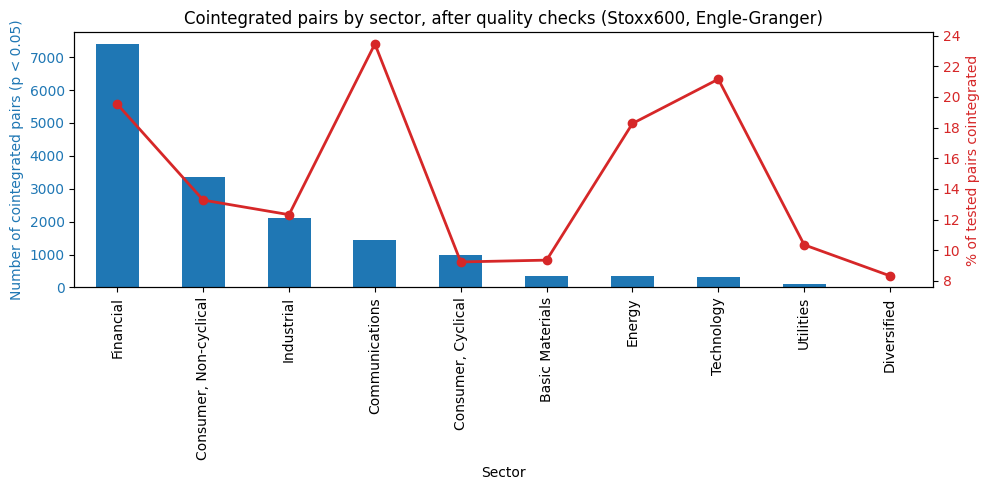

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 5))
summary['pairs_cointegrated'].plot(kind='bar', ax=ax1, color='#1f77b4')
ax1.set_ylabel('Number of cointegrated pairs (p < 0.05)', color='#1f77b4')
ax1.set_xlabel('Sector')
ax1.tick_params(axis='y', labelcolor='#1f77b4')

ax2 = ax1.twinx()
ax2.plot(ax1.get_xticks(), summary['percentage_cointegrated'] * 100, color='#d62728', marker='o', linewidth=2)
ax2.set_ylabel('% of tested pairs cointegrated', color='#d62728')
ax2.tick_params(axis='y', labelcolor='#d62728')

ax1.set_title('Cointegrated pairs by sector, after quality checks (Stoxx600, Engle-Granger)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

* **Financial** has by far the most cointegrated pairs in absolute terms (7,385), but this is simply because it's the largest sector (37,827 pairs tested), not because its stocks are more strongly related, in fact its cointegration rate (19.5%) is high but not the highest.
* **Communications** and **Technology** are the most cohesive sectors in relative terms, with 23.5% and 21.2% of their pairs cointegrated. **Energy** also shows a notably high percentage (18.3%).
* At the other end, **Consumer Cyclical**, **Basic Materials**, and **Utilities** show the lowest percentages among sectors (9-10%).
* **Diversified** has too few pairs tested (24 pairs) to draw any conclusion from.



***Top-15 pairs***

The 15 pairs with the lowest p-value, after all three quality checks are the following. This will be the starting point for the detailed analysis in the next phase.


In [ ]:
top_pairs = pairs_final.sort_values(['p_min', 'n_obs'], ascending=[True, False]).head(15).reset_index(drop=True)
top_pairs[['settore', 'A', 'B', 'p_min', 'n_obs', 'return_corr']].rename(columns={'settore':'sector'})

,sector,A,B,p_min,n_obs,return_corr
0,Financial,TPEIR GA Equity,AMUN FP Equity,0.000000e+00,798,0.272992
1,"Consumer, Non-cyclical",AUT IM Equity,ATL IM Equity,0.000000e+00,449,0.284418
2,"Consumer, Non-cyclical",MHG NO Equity,ITRK LN Equity,1.881130e-29,4312,0.123845
3,Financial,ETE GA Equity,ABN NA Equity,3.526262e-29,792,0.211653
4,Financial,ETE GA Equity,PST IM Equity,9.074041e-29,810,0.238130
5,Financial,SCO FP Equity,DEQ GY Equity,1.541019e-28,1206,0.041536
6,Financial,SCR FP Equity,DEQ GY Equity,2.662412e-28,4185,0.226533
7,"Consumer, Non-cyclical",MHG NO Equity,EDN IM Equity,2.557062e-23,2551,0.080406
8,"Consumer, Non-cyclical",MHG NO Equity,ORP FP Equity,4.934763e-23,4339,0.111928
9,Financial,TPEIR GA Equity,PST IM Equity,2.249539e-22,810,0.236211


It is important to notice that there are recurring tickers, something we will need to account for later when building the portfolio.


---
## ***Phase 3 - Validation***

In this phase we check whether the cointegrated pairs found in Phase 2 actually hold up on unseen data.

To test this properly, each pair's data is split into a training period (70%) and a test period (30%). The relationship between the two stocks is estimated only on the training data, and the resulting spread is then tested for stationarity, using the Augmented Dickey-Fuller (ADF) test, in both periods.

The ADF test verifies whether the spread is stationary. A pair is only considered validated if the spread passes this test in both the training period and, more importantly, the test period.

### **Why the lowest p-value is not enough?**

The pair with the lowest p-value from Phase 2 is `TPEIR GA` and `AMUN FP`.


In [ ]:
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
warnings.filterwarnings('ignore')

def validate_out_of_sample(tk_x, tk_y, train_frac=0.7):
    x = prices[tk_x].dropna()
    y = prices[tk_y].dropna()
    common = x.index.intersection(y.index)
    x, y = x.loc[common], y.loc[common]
    n = len(common)
    split = int(n * train_frac)
    x_tr, y_tr = x.iloc[:split], y.iloc[:split]
    x_te, y_te = x.iloc[split:], y.iloc[split:]

    X = sm.add_constant(x_tr)
    model = sm.OLS(y_tr, X).fit()
    alpha, beta = model.params.iloc[0], model.params.iloc[1]

    spread_tr = y_tr - (alpha + beta * x_tr)
    spread_te = y_te - (alpha + beta * x_te)

    p_tr = adfuller(spread_tr, maxlag=1)[1]
    p_te = adfuller(spread_te, maxlag=1)[1]
    return p_tr, p_te, beta, model.rsquared, n

p_tr, p_te, beta, r2, n = validate_out_of_sample('TPEIR GA Equity', 'AMUN FP Equity')
print(f"TPEIR GA / AMUN FP  (the best by p-value in Phase 2)")
print(f"  n_obs={n}, R^2={r2:.4f}")
print(f"  ADF train: p={p_tr:.5f}  {'PASSED' if p_tr<0.05 else 'NOT passed'}")
print(f"  ADF test:  p={p_te:.5f}  {'PASSED' if p_te<0.05 else 'NOT passed'}")

TPEIR GA / AMUN FP  (the best by p-value in Phase 2)
  n_obs=798, R^2=0.0067
  ADF train: p=0.94581  NOT passed
  ADF test:  p=0.86311  NOT passed


The relationship fails already on the training period, and also on the test period, despite its p-value being essentially zero in Phase 2. So a strong p-value on the full sample is not enough on its own.

### **Widening the search**

Since the single best candidate by p-value fails validation, there is no reason to trust the next-best one either.

Instead of picking one more pair by hand, the same out-of-sample validation is applied to a wider set of candidates, to see how many hold up.

In [ ]:
import time

candidates = pairs_final[pairs_final['n_obs'] > 1000].sort_values('p_min').head(150).reset_index(drop=True)

t0 = time.time()
results = []
for _, r in candidates.iterrows():
    try:
        p_tr, p_te, beta, r2, n = validate_out_of_sample(r['A'], r['B'])
        results.append({'settore': r['settore'], 'A': r['A'], 'B': r['B'], 'n_obs': n,
                        'p_train': p_tr, 'p_test': p_te, 'beta': beta, 'r2': r2})
    except Exception:
        continue

validation = pd.DataFrame(results)

robust = validation[(validation['p_train'] < 0.05) & (validation['p_test'] < 0.05)]
print(f"\nPairs passing ADF both in train and test: {len(robust)} out of {len(validation)} tested ({len(robust)/len(validation):.1%})")


Pairs passing ADF both in train and test: 4 out of 150 tested (2.7%)


Only 4 pairs out of 150 (2.7%) pass the ADF test in both the training and test periods.

In [ ]:
sector_name_lookup = dict(zip(sector_map['ticker'], sector_map['nome']))

def stock_quality(tk):
    s = prices[tk].dropna()
    return f"{s.index.min().date()} -> {s.index.max().date()}"

robust_display = robust.copy()

robust_display['period_A'] = robust_display['A'].apply(stock_quality)
robust_display['period_B'] = robust_display['B'].apply(stock_quality)

robust_display = robust_display.sort_values('p_test')

robust_display[['settore','A','period_A','B','period_B',
                'n_obs','p_train','p_test','r2']].rename(columns={'settore':'sector'})

,sector,A,period_A,B,period_B,n_obs,p_train,p_test,r2
143,Financial,DEXB BB Equity,2002-01-01 -> 2018-11-30,BKIA SQ Equity,2011-07-20 -> 2018-11-30,1923,2.651712e-02,0.018394,0.567172
24,Financial,RSA LN Equity,2002-01-01 -> 2018-11-30,COL SQ Equity,2002-05-31 -> 2018-11-30,4306,6.459497e-08,0.024090,0.476308
107,Financial,RSA LN Equity,2002-01-01 -> 2018-11-30,CS FP Equity,2002-01-01 -> 2018-11-30,4414,4.851798e-02,0.035602,0.264780
74,Communications,VIV FP Equity,2002-01-01 -> 2018-11-30,MMB FP Equity,2002-01-01 -> 2018-11-30,4414,2.454171e-04,0.042326,0.433138


We select `VIV FP` / `MMB FP`, because among the candidates, it has the second-strongest training p-value, and while its testing p-value is the weakest of the four, it still clears the 5% significance threshold and, unlike the others, neither company has a comparable crisis event in its history.

### **Estimating the relationship**

The pair's data is split into a training period (70%) and a test period (30%).

In [ ]:
x = prices['VIV FP Equity'].dropna()
y = prices['MMB FP Equity'].dropna()

common = x.index.intersection(y.index)
x, y = x.loc[common], y.loc[common]

n = len(common)
split = int(n * 0.7)
x_train, y_train = x.iloc[:split], y.iloc[:split]
x_test, y_test = x.iloc[split:], y.iloc[split:]

The hedge ratio (beta) tells us in what proportion to combine the two stocks to build the spread:
$$spread = MMB - (alpha + beta * VIV)$$
We estimate it with a simple linear regression, using only the train data.

In [ ]:
import statsmodels.api as sm

X_train = sm.add_constant(x_train)
model = sm.OLS(y_train, X_train).fit()
alpha, beta = model.params.iloc[0], model.params.iloc[1]

print(f"Hedge ratio (beta): {beta:.5f}")
print(f"Intercept (alpha): {alpha:.4f}")
print(f"Regression R^2: {model.rsquared:.4f}")

Hedge ratio (beta): 1.43725
Intercept (alpha): 9.6258
Regression R^2: 0.4331


- The hedge ratio of 1.44 is positive, meaning the two stocks tend to move in the same direction rather than opposite ones, and its magnitude indicates that a €1 move in `VIV FP` tends to be matched by a €1.44 move in `MMB FP`.


- The R^2 of 0.43 indicates a moderate linear relationship between the two stocks: it is meaningfully positive, but not strong enough on its own to predict one price from the other with much precision.

### **ADF test**

The spread, built using the hedge ratio estimated on the training data, is tested for stationarity with the ADF test, separately on the training and test periods. The pair is only trusted if the spread passes this test in both periods.

In [ ]:
from statsmodels.tsa.stattools import adfuller

spread_train = y_train - (alpha + beta * x_train)
spread_test = y_test - (alpha + beta * x_test)

adf_train = adfuller(spread_train, maxlag=1)
adf_test = adfuller(spread_test, maxlag=1)

print(f"ADF on residual (TRAIN): statistic={adf_train[0]:.3f}, p-value={adf_train[1]:.5f}")
print(f"ADF on residual (TEST):  statistic={adf_test[0]:.3f}, p-value={adf_test[1]:.5f}")
print()
print("The test is passed (stationary spread) if the p-value is below 0.05.")
print(f"Train: {'PASSED' if adf_train[1] < 0.05 else 'NOT passed'}")
print(f"Test:  {'PASSED' if adf_test[1] < 0.05 else 'NOT passed'}")

ADF on residual (TRAIN): statistic=-4.446, p-value=0.00025
ADF on residual (TEST):  statistic=-2.927, p-value=0.04233

The test is passed (stationary spread) if the p-value is below 0.05.
Train: PASSED
Test:  PASSED


The spread passes the ADF test in both periods, confirming the pair is genuinely cointegrated.

However, the test-period p-value (0.042), while still below the 5% threshold, is noticeably weaker than the train-period one (0.00025).

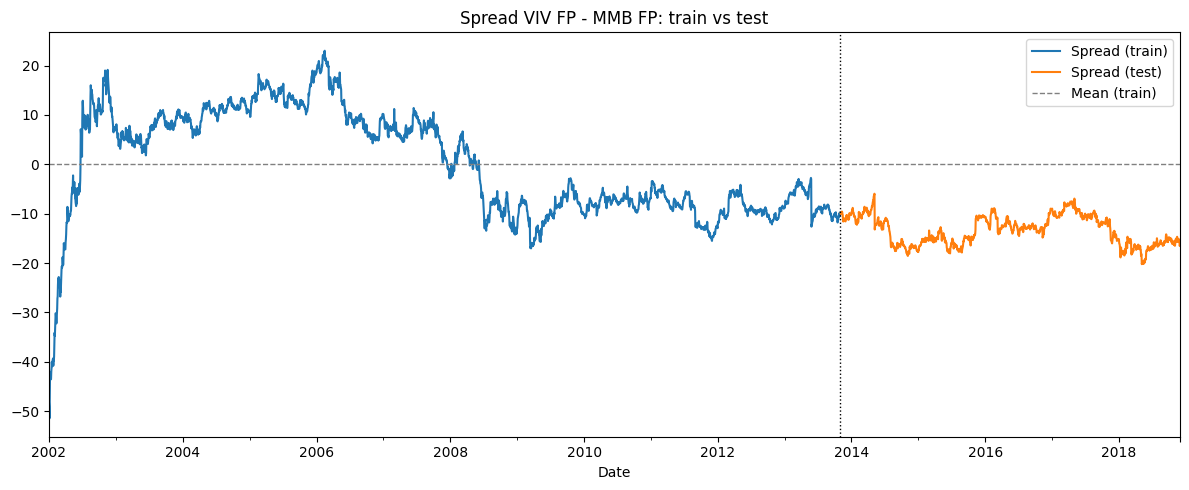

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))
spread_train.plot(ax=ax, label='Spread (train)', color='#1f77b4')
spread_test.plot(ax=ax, label='Spread (test)', color='#ff7f0e')
ax.axhline(spread_train.mean(), color='gray', linestyle='--', linewidth=1, label='Mean (train)')
ax.axvline(spread_train.index[-1], color='black', linestyle=':', linewidth=1)
ax.set_title('Spread VIV FP - MMB FP: train vs test')
ax.legend()
plt.tight_layout()
plt.show()

After an initial adjustment, the spread oscillates around a higher level until 2008, then shifts down following the financial crisis, remaining there for the rest of the training period. The test period continues in that same lower band, consistent with the ADF test passing in both periods.

***Mean-reversion half-life***

The half-life measures how quickly the spread reverts back to its average after moving away from it.

It is derived from the mean-reversion coefficient (lambda), estimated by regressing the change in the spread on its own previous value. A negative lambda confirms mean reversion, meaning the spread tends to move back toward its mean rather than drift away from it.

The half-life converts lambda into a more intuitive time scale, as it indicates the number of trading days it takes to close half the distance back to the mean.

In [ ]:
spread_lag = spread_train.shift(1).dropna()
spread_delta = spread_train.diff().dropna()
spread_lag = spread_lag.loc[spread_delta.index]

hl_model = sm.OLS(spread_delta, sm.add_constant(spread_lag)).fit()
lam = hl_model.params.iloc[1]
half_life = -np.log(2) / lam if lam < 0 else np.nan

print(f"Mean-reversion coefficient (lambda): {lam:.5f}")
print(f"Half-life: {half_life:.1f} trading days")

Mean-reversion coefficient (lambda): -0.00529
Half-life: 131.0 trading days


The mean-reversion coefficient is negative (-0.00529), confirming mean reversion, which translates into a half-life of 131 trading days (about 6 months).

It is a fairly slow reversion, which means a trade on this pair could stay open for months before it's worth closing.

***Z-score of the spread***

The spread is converted into a z-score, standardized using the mean and standard deviation from the training period. This is the signal that will be used to define entry and exit rules in the next phase.

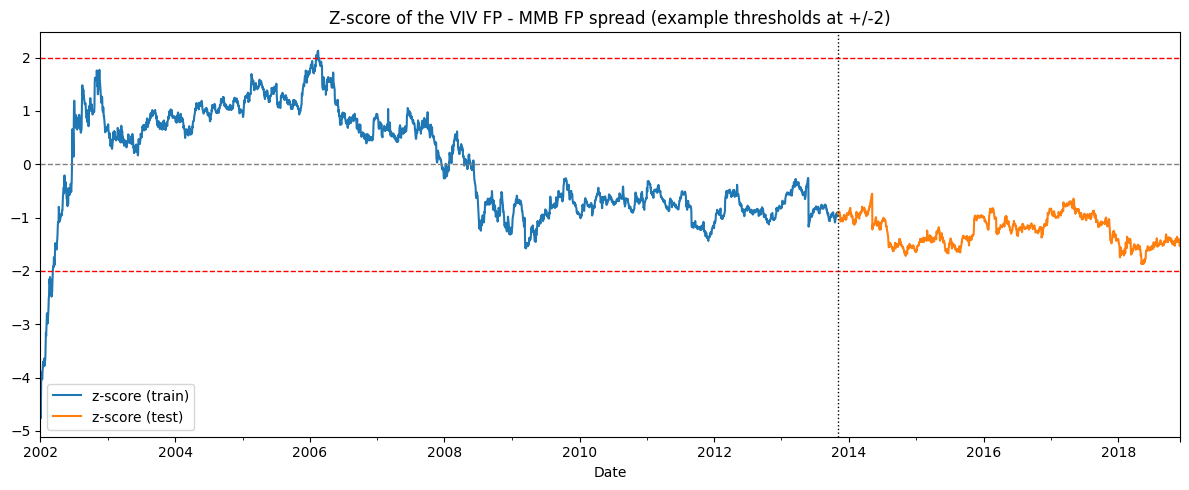

In [ ]:
mu_train = spread_train.mean()
sigma_train = spread_train.std()

z_train = (spread_train - mu_train) / sigma_train
z_test = (spread_test - mu_train) / sigma_train

fig, ax = plt.subplots(figsize=(12, 5))
z_train.plot(ax=ax, label='z-score (train)', color='#1f77b4')
z_test.plot(ax=ax, label='z-score (test)', color='#ff7f0e')
for level, color in [(2, 'red'), (-2, 'red'), (0, 'gray')]:
    ax.axhline(level, color=color, linestyle='--', linewidth=1)
ax.axvline(z_train.index[-1], color='black', linestyle=':', linewidth=1)
ax.set_title('Z-score of the VIV FP - MMB FP spread (example thresholds at +/-2)')
ax.legend()
plt.tight_layout()
plt.show()

In the test period, the z-score never reaches the ±2 threshold shown here. This is a limitation of using fixed thresholds, which Phase 4 addresses with a different approach.

---
## ***Phase 4 — Portfolio***

The same out-of-sample validation used in Phase 3 for a single pair is now applied to every remaining candidate pair.

In [ ]:
t0 = time.time()
full_results = []
for _, r in pairs_final.iterrows():
    try:
        p_tr, p_te, beta, r2, n = validate_out_of_sample(r['A'], r['B'])
        full_results.append({'settore': r['settore'], 'A': r['A'], 'B': r['B'],
                             'n_obs': n, 'p_train': p_tr, 'p_test': p_te})
    except Exception:
        continue

full_validation = pd.DataFrame(full_results)

robust = full_validation[(full_validation['p_train']<0.05) & (full_validation['p_test']<0.05)]
print(f"Robust pairs (ADF passed in train and test): {len(robust)} out of {len(full_validation)} ({len(robust)/len(full_validation):.2%})")

Robust pairs (ADF passed in train and test): 588 out of 16402 (3.58%)


Only 588 pairs out of 16,402 (3.58%) pass the validation both in train and in test.

This confirms, at full scale, what the single-pair example in Phase 3 already suggested: a strong cointegration p-value on the full sample is a weak predictor of future stability.

Still, 588 pairs are more than enough to build a well-diversified portfolio.

### ***Portfolio selection***

From the robust pairs, we build a diversified portfolio of 20 pairs with the following rules:

- each stock can appear in at most one pair
- each sector can contribute at most 5 pairs
- only pairs with at least 750 common observations are considered
- pairs are selected in order of their test-period p-value, from strongest to weakest.

We target 20 pairs as a practical balance: enough for meaningful diversification across stocks and sectors, while keeping the portfolio small enough to review and explain.

In [ ]:
candidates = robust[robust['n_obs'] >= 750].sort_values('p_test')

N_TARGET = 20
MAX_PER_SECTOR = 5
used, sector_count, final_portfolio = set(), {}, []
for _, r in candidates.iterrows():
    if r['A'] in used or r['B'] in used:
        continue
    if sector_count.get(r['settore'], 0) >= MAX_PER_SECTOR:
        continue
    final_portfolio.append(r)
    used.add(r['A']); used.add(r['B'])
    sector_count[r['settore']] = sector_count.get(r['settore'], 0) + 1
    if len(final_portfolio) >= N_TARGET:
        break

final_portfolio = pd.DataFrame(final_portfolio)
print(f"Final portfolio:")
final_portfolio[['settore','A','B','n_obs','p_train','p_test']].rename(columns={'settore':'sector'})

Final portfolio:


,sector,A,B,n_obs,p_train,p_test
16243,Technology,DLG GY Equity,IOT LN Equity,1518,0.045352,4.140196e-12
16310,Utilities,SZE FP Equity,EDF FP Equity,1198,0.026909,1.088756e-07
4645,"Consumer, Non-cyclical",BEI GY Equity,GRF SQ Equity,3273,0.020564,2.639517e-07
10763,Financial,CSGN SE Equity,BPE IM Equity,4414,0.000768,9.626802e-06
9700,Financial,RCEA NA Equity,AGF FP Equity,1421,0.047596,3.785195e-05
14549,Industrial,TNU FP Equity,ECM LN Equity,1687,0.031652,4.073270e-05
3547,"Consumer, Non-cyclical",KYG ID Equity,CBRY LN Equity,2134,0.020399,5.344209e-05
13795,Financial,SPL PW Equity,ABN NA Equity,792,0.020990,1.047133e-04
13209,Financial,COFB BB Equity,SR NA Equity,1752,0.014165,1.445382e-04
13488,Financial,DLG LN Equity,SHB LN Equity,1603,0.002174,1.585059e-04


The final portfolio spans 7 of the 10 sectors, with Financial, Industrial, and Consumer Non-cyclical each hitting the cap of 5 pairs. This is unsurprising, since they were also the largest sectors in the original search.

`VIV FP` / `MMB FP`, the pair examined in Phase 3, passed validation but didn't make it into the final portfolio, because `VIV FP` is also part of a stronger pair (`JAZ SQ` / `VIV FP`).

### ***Trading rules***

Each pair is traded using a z-score of its spread. The spread's mean and standard deviation are recalculated on a rolling 52-week window, rather than fixed once on the training period, so the z-score adapts as market conditions change, addressing the issue found in Phase 3, where a fixed, train-only z-score produced no trading signal at all in the test period.

The hedge ratio, on the other hand, is estimated once on the training data and kept fixed for the whole test period.

We do not set a maximum holding period for open positions. A position is only closed when the z-score returns within the exit band or triggers the stop-loss.

Positions are rebalanced weekly, as required by the assignment.



In [ ]:
def generate_signals(z, entry=2.0, exit_=0.5, stop=3.5):
    pos = np.zeros(len(z))
    p = 0
    for t in range(len(z)):
        if p == 0:
            if z[t] < -entry: p = 1
            elif z[t] > entry: p = -1
        elif p == 1:
            if z[t] >= -exit_ or z[t] < -stop: p = 0
        elif p == -1:
            if z[t] <= exit_ or z[t] > stop: p = 0
        pos[t] = p
    return pos

def backtest_spread(spread, pos, y0, x0, beta, periods_per_year=52):
    notional = y0 + abs(beta) * x0
    dpnl = pos[:-1] * np.diff(spread)
    dpnl = np.concatenate([[0], dpnl])
    ret = dpnl / notional
    sharpe = np.sqrt(periods_per_year) * ret.mean() / ret.std() if ret.std() > 0 else 0
    equity = 1 + np.cumsum(ret)
    peak = np.maximum.accumulate(equity)
    dd = (equity - peak) / peak
    pos_chg = np.diff(np.concatenate([[0], pos]))
    n_trades = int(((pos_chg != 0) & (pos == 0)).sum())
    return {'ret': ret, 'equity': equity, 'dd': dd, 'sharpe': sharpe,
            'max_dd': dd.min(), 'n_trades': n_trades, 'total_return': equity[-1] - 1}

def backtest_pair(tk_x, tk_y, train_frac=0.7, rolling=52):
    x_d = prices[tk_x].dropna(); y_d = prices[tk_y].dropna()
    common = x_d.index.intersection(y_d.index)
    x_d, y_d = x_d.loc[common], y_d.loc[common]
    n = len(common); split = int(n * train_frac); split_date = common[split]

    x_w = x_d.resample('W-FRI').last().dropna()
    y_w = y_d.resample('W-FRI').last().dropna()
    common_w = x_w.index.intersection(y_w.index)
    x_w, y_w = x_w.loc[common_w], y_w.loc[common_w]

    x_tr_w = x_w[x_w.index < split_date]
    y_tr_w = y_w[y_w.index < split_date]
    X = sm.add_constant(x_tr_w)
    model = sm.OLS(y_tr_w, X).fit()
    alpha, beta = model.params.iloc[0], model.params.iloc[1]

    spread_w = y_w - (alpha + beta * x_w)
    mu_roll = spread_w.rolling(rolling).mean()
    sigma_roll = spread_w.rolling(rolling).std()
    z_roll = (spread_w - mu_roll) / sigma_roll

    mask_test = z_roll.index >= split_date
    z_te = z_roll[mask_test].dropna()
    spread_te = spread_w.loc[z_te.index]
    x_te = x_w.loc[z_te.index]

    pos = generate_signals(z_te.values, entry=2.0, exit_=0.5, stop=3.5)
    bt = backtest_spread(spread_te.values, pos, y_w.loc[z_te.index[0]], x_te.iloc[0], beta)
    bt['ret_series'] = pd.Series(bt['ret'], index=z_te.index)
    return bt

backtest_results = {}
for _, r in final_portfolio.iterrows():
    name = f"{r['A']} / {r['B']}"
    try:
        backtest_results[name] = backtest_pair(r['A'], r['B'])
    except Exception as e:
        print(f"Error on {name}: {e}")

print(f"Pairs with completed backtest: {len(backtest_results)}")

Pairs with completed backtest: 20


All 20 pairs selected in the previous step produce a complete backtest (20/20), confirming that the pipeline runs cleanly on every pair, including the shorter-history ones.


### ***Equal-weight portfolio and comparison with the benchmark***

We combine the pairs at equal weights: each of the 20 pairs contributes an equal share of the portfolio's capital. Where a pair has no data yet or has run out, its contribution for that week is zero, so the portfolio is diversified over time as well as across stocks and sectors, rather than being fully invested at every point.

We use equal weighting for simplicity: more sophisticated alternatives, like volatility-scaled or risk-parity weighting, are not explored here.

The portfolio's return, volatility, maximum drawdown, and Sharpe ratio are compared against the same measures for the Stoxx600 benchmark, over the same period.


In [ ]:
pair_rets = pd.concat([v['ret_series'] for v in backtest_results.values()], axis=1)
pair_rets.columns = list(backtest_results.keys())
pair_rets_filled = pair_rets.fillna(0)

port_ret = pair_rets_filled.mean(axis=1)
port_equity = (1 + port_ret).cumprod()
port_peak = port_equity.cummax()
port_dd = (port_equity - port_peak) / port_peak
port_sharpe = np.sqrt(52) * port_ret.mean() / port_ret.std() if port_ret.std() > 0 else 0

# how many pairs have real data (not zero-filled) in each week
n_active = pair_rets.notna().sum(axis=1)

# SXXP benchmark over the same overall period, same weekly frequency
ac_w = ac_series.resample('W-FRI').last().dropna()
ac_test = ac_w.loc[port_ret.index[0]:port_ret.index[-1]]
bench_ret = ac_test.pct_change().fillna(0)
bench_equity = (1 + bench_ret).cumprod()
bench_peak = bench_equity.cummax()
bench_dd = (bench_equity - bench_peak) / bench_peak
bench_sharpe = np.sqrt(52) * bench_ret.mean() / bench_ret.std() if bench_ret.std() > 0 else 0

summary_table = pd.DataFrame({
    'Portfolio': [
        f"{port_equity.iloc[-1] - 1:.1%}",
        f"{port_sharpe:.2f}",
        f"{port_dd.min():.1%}",
        f"{port_ret.std() * np.sqrt(52):.1%}",
    ],
    'Benchmark': [
        f"{bench_equity.iloc[-1] - 1:.1%}",
        f"{bench_sharpe:.2f}",
        f"{bench_dd.min():.1%}",
        f"{bench_ret.std() * np.sqrt(52):.1%}",
    ],
}, index=['Total return', 'Annualized Sharpe', 'Max drawdown', 'Annualized volatility'])
summary_table

,Portfolio,Benchmark
Total return,20.9%,36.5%
Annualized Sharpe,1.30,0.22
Max drawdown,-1.5%,-60.2%
Annualized volatility,1.1%,18.3%


The strategy trades off some return for a lot of safety.

The portfolio delivers a Sharpe ratio nearly 6x higher than the benchmark (1.30 vs 0.22), with an almost inexistent volatility (1.1% vs 18.3% annualized). On top of that, drawdown tells the same story: the benchmark loses 60.2% at its worst point, while the portfolio's maximum drawdown is just -1.5%.

However, total return is 20.9% for the portfolio versus 36.5% for the benchmark over the full period. This doesn't mean the strategy is worse, it just means it's taking on much less risk.


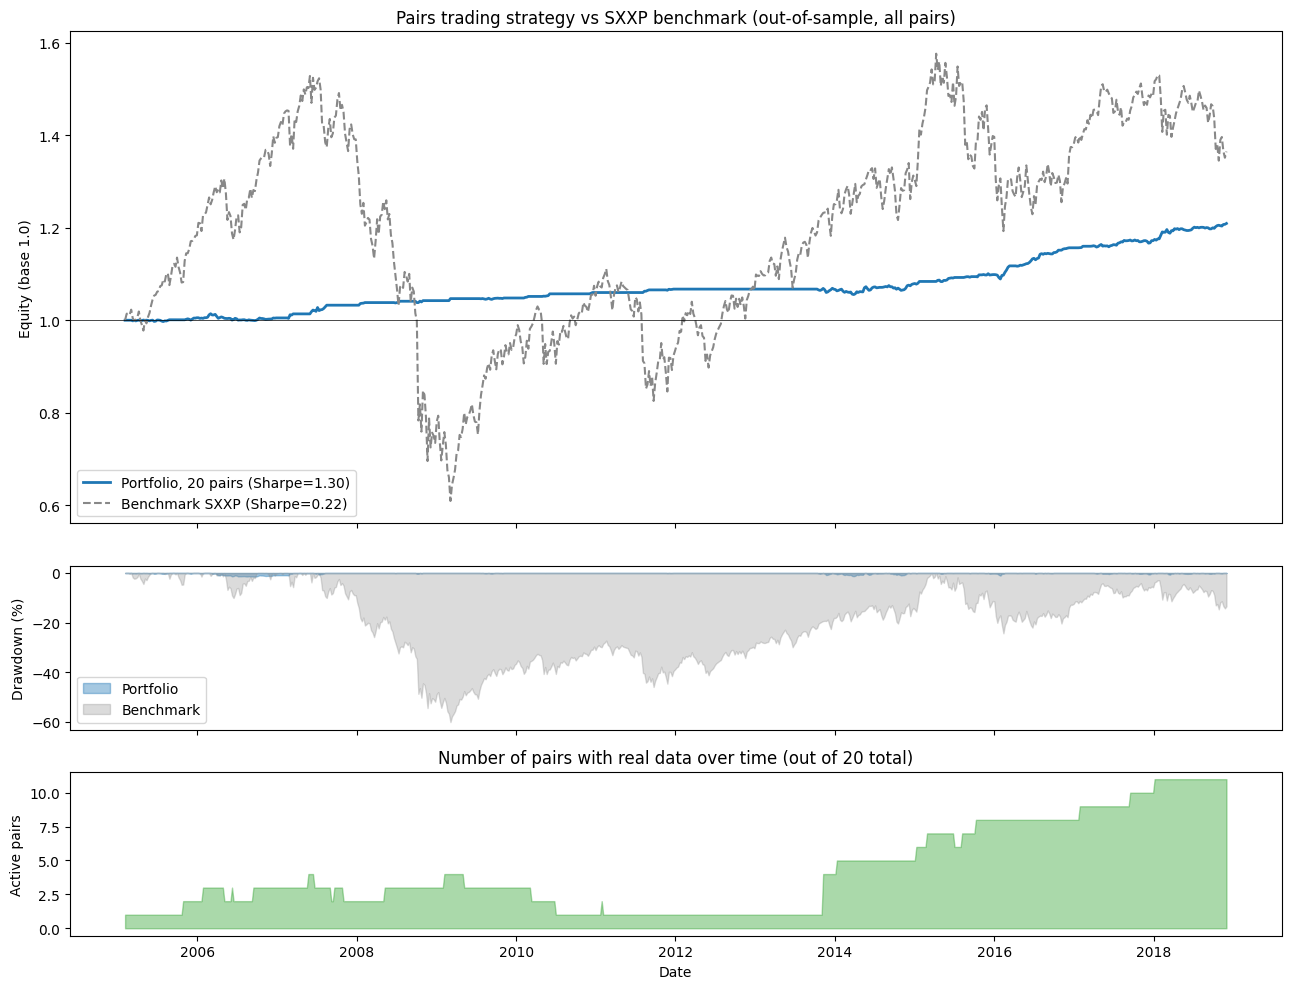

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True, gridspec_kw={'height_ratios':[3,1,1]})

axes[0].plot(port_equity.index, port_equity, color='#1f77b4', lw=2, label=f'Portfolio, 20 pairs (Sharpe={port_sharpe:.2f})')
axes[0].plot(bench_equity.index, bench_equity, color='#888', lw=1.5, ls='--', label=f'Benchmark SXXP (Sharpe={bench_sharpe:.2f})')
axes[0].axhline(1, color='black', lw=0.5)
axes[0].set_ylabel('Equity (base 1.0)')
axes[0].set_title('Pairs trading strategy vs SXXP benchmark (out-of-sample, all pairs)')
axes[0].legend()

axes[1].fill_between(port_dd.index, port_dd*100, 0, color='#1f77b4', alpha=0.4, label='Portfolio')
axes[1].fill_between(bench_dd.index, bench_dd*100, 0, color='#888', alpha=0.3, label='Benchmark')
axes[1].set_ylabel('Drawdown (%)')
axes[1].legend()

axes[2].fill_between(n_active.index, n_active, 0, color='#2ca02c', alpha=0.4)
axes[2].set_ylabel('Active pairs')
axes[2].set_xlabel('Date')
axes[2].set_title('Number of pairs with real data over time (out of 20 total)')

plt.tight_layout()
plt.show()

Here we can see the trade-off between return and safety.

In the top panel, the benchmark shows swings, including the sharp collapse during the 2008 financial crisis. The portfolio, by contrast, follows a much smoother and steadily increasing path throughout the same period.

The difference is even more visible in the second panel, where the benchmark's drawdown reaches -60% during the crisis and remains substantial for several years, while the portfolio's drawdown stays close to zero for almost the entire sample.

The bottom panel helps explain why the portfolio's growth is relatively slow: only 1 to 4 pairs are active at any given time in the earlier part of the sample (since the dataset is free of survivorship bias and different stocks enter and exit their price histories at different points). Only from around 2014 onward, more pairs trade simultaneously, which coincides with a slightly faster increase in the portfolio's equity curve.

### ***Robustness check: pairs with near-complete history only***

As a check, the same portfolio construction and backtest are repeated restricting the candidates to pairs with a fully overlapping trading history (2013-2018), so all pairs can be active simultaneously.


In [ ]:
long_candidates = robust[robust['n_obs'] >= 4000].sort_values('p_test')

used2, sector_count2, long_portfolio = set(), {}, []
for _, r in long_candidates.iterrows():
    if r['A'] in used2 or r['B'] in used2:
        continue
    if sector_count2.get(r['settore'], 0) >= MAX_PER_SECTOR:
        continue
    long_portfolio.append(r)
    used2.add(r['A']); used2.add(r['B'])
    sector_count2[r['settore']] = sector_count2.get(r['settore'], 0) + 1
    if len(long_portfolio) >= N_TARGET:
        break
long_portfolio = pd.DataFrame(long_portfolio)

long_results = {}
for _, r in long_portfolio.iterrows():
    name = f"{r['A']} / {r['B']}"
    try:
        long_results[name] = backtest_pair(r['A'], r['B'])
    except Exception:
        continue

pair_rets_L = pd.concat([v['ret_series'] for v in long_results.values()], axis=1)
pair_rets_L.columns = list(long_results.keys())
port_ret_L = pair_rets_L.mean(axis=1)
port_equity_L = (1 + port_ret_L).cumprod()
port_sharpe_L = np.sqrt(52) * port_ret_L.mean() / port_ret_L.std() if port_ret_L.std() > 0 else 0
port_dd_L = (port_equity_L - port_equity_L.cummax()) / port_equity_L.cummax()

ac_test_L = ac_w.loc[port_ret_L.index[0]:port_ret_L.index[-1]]
bench_ret_L = ac_test_L.pct_change().fillna(0)
bench_equity_L = (1 + bench_ret_L).cumprod()
bench_sharpe_L = np.sqrt(52) * bench_ret_L.mean() / bench_ret_L.std() if bench_ret_L.std() > 0 else 0
bench_dd_L = (bench_equity_L - bench_equity_L.cummax()) / bench_equity_L.cummax()

summary_table_L = pd.DataFrame({
    'Portfolio (long history)': [
        f"{port_equity_L.iloc[-1] - 1:.1%}",
        f"{port_sharpe_L:.2f}",
        f"{port_dd_L.min():.1%}",
    ],
    'Benchmark': [
        f"{bench_equity_L.iloc[-1] - 1:.1%}",
        f"{bench_sharpe_L:.2f}",
        f"{bench_dd_L.min():.1%}",
    ],
}, index=['Total return', 'Annualized Sharpe', 'Max drawdown'])
summary_table_L

,Portfolio (long history),Benchmark
Total return,31.7%,17.2%
Annualized Sharpe,2.15,0.27
Max drawdown,-2.9%,-24.3%


Restricting to pairs with near-complete history pushes the Sharpe ratio even higher, from 1.30 to 2.15, while the benchmark's Sharpe stays low (0.27).

It is interesting that this time the portfolio doesn't just win on risk — it also beats the benchmark on total return (31.7% vs 17.2%). This is because from 2013 onward more pairs are active simultaneously.

The drawdown pattern is similar to before, though less extreme since this shorter window excludes 2008: -2.9% for the portfolio versus -24.3% for the benchmark.

This check confirms that the earlier results weren't just an artifact of having few pairs active in the early years. The strategy holds up, and even improves, when tested on a period where the portfolio is more fully deployed.


### ***Saving results for future comparisons***



In [ ]:
eu_results = {
    'main': {
        'sharpe': port_sharpe, 'max_dd': port_dd.min(), 'total_return': port_equity.iloc[-1] - 1,
        'bench_sharpe': bench_sharpe, 'bench_max_dd': bench_dd.min(), 'bench_total_return': bench_equity.iloc[-1] - 1,
        'period': f"{port_ret.index[0].date()} to {port_ret.index[-1].date()}"
    },
    'long': {
        'sharpe': port_sharpe_L, 'max_dd': port_dd_L.min(), 'total_return': port_equity_L.iloc[-1] - 1,
        'bench_sharpe': bench_sharpe_L, 'bench_max_dd': bench_dd_L.min(), 'bench_total_return': bench_equity_L.iloc[-1] - 1,
        'period': f"{port_ret_L.index[0].date()} to {port_ret_L.index[-1].date()}"
    }
}

---
# **Part 2 - US Universe (S&P500)**
The same pipeline used for Europe, applied without changes to its logic to the S&P500 universe.

## ***Phase 1 - Setup, loading, and data cleaning***
### **Data loading**

As for Europe, only the three relevant sheets are loaded.

In [ ]:
path = '/content/drive/My Drive/Colab Notebooks/FMA/SPX500.xlsm'

price_raw  = pd.read_excel(path, sheet_name='Price daily', header=None, engine='openpyxl')
ac_raw     = pd.read_excel(path, sheet_name='AC',          header=None, engine='openpyxl')
sector_raw = pd.read_excel(path, sheet_name='Sector',       header=None, engine='openpyxl')

print('Price daily (raw):', price_raw.shape)
print('AC (raw):         ', ac_raw.shape)
print('Sector (raw):     ', sector_raw.shape)

Price daily (raw): (7546, 1356)
AC (raw):          (7545, 6)
Sector (raw):      (3, 1355)


### **Data cleaning**
The same cleaning logic used for Europe is applied here.

First, the `Price daily` sheet was cleaned.

In [ ]:
tickers = price_raw.iloc[0, 1:]
names   = price_raw.iloc[1, 1:]
dates   = pd.to_datetime(price_raw.iloc[2:, 0])

prices = price_raw.iloc[2:, 1:]
prices.columns = tickers.values
prices.index = dates
prices.index.name = 'Date'

prices = prices.apply(pd.to_numeric, errors='coerce')

print('Price daily (clean):', prices.shape)
print('Period:', prices.index.min().date(), '->', prices.index.max().date())

Price daily (clean): (7544, 1355)
Period: 1990-01-02 -> 2018-11-30


The US series runs from **1990-01-02 to 2018-11-30**, which is considerably longer than the European series (2002-2018).

Then, the `AC` sheet was cleaned.

In [ ]:
ac_dates = pd.to_datetime(ac_raw.iloc[2:, 0])
ac_series = pd.to_numeric(ac_raw.iloc[2:, 1], errors='coerce')
ac_series.index = ac_dates
ac_series.index.name = 'Date'
ac_series.name = 'SPX'

print('AC (clean):', ac_series.shape)

AC (clean): (7543,)


Finally, the `Sector` sheet was cleaned.

In [ ]:
sec_tickers = sector_raw.iloc[0, 1:]
sec_names   = sector_raw.iloc[1, 1:]
sec_sector  = sector_raw.iloc[2, 1:]

sector_map = pd.DataFrame({
    'ticker': sec_tickers.values,
    'nome': sec_names.values,
    'settore': sec_sector.values
}).dropna(subset=['ticker'])

sector_map['settore'].rename('sector').value_counts()

,count
sector,
"Consumer, Non-cyclical",247
Financial,226
"Consumer, Cyclical",180
Industrial,165
Technology,147
Communications,140
Energy,92
Basic Materials,62
Utilities,57


There are 8 stocks with a sector field of `#N/A Invalid Security`, so they need to be removed.

A new sector was found (`Funds`) for 27 equities. Looking at the actual names behind the Funds label, these are real operating companies that were later delisted, acquired, or merged. The Funds label therefore looks like a classification error, so they are removed.


In [ ]:
invalid_labels = ['#N/A Invalid Security', 'Funds']
n_before = sector_map.shape[0]
sector_map = sector_map[~sector_map['settore'].isin(invalid_labels)].copy()
print(f"Removed {n_before - sector_map.shape[0]} tickers with an unusable sector label.")

Removed 35 tickers with an unusable sector label.


### **Data quality check**
The same missing-data and stuck-price checks used for Europe are applied here.


***Missing data***

In [ ]:
first_valid = prices.apply(lambda col: col.first_valid_index())
last_valid  = prices.apply(lambda col: col.last_valid_index())
lifespan_years = (last_valid - first_valid).dt.days / 365.25

pct_interior_gap = prices.apply(interior_gaps)

quality = pd.DataFrame({
    'years_of_history': lifespan_years,
    'pct_interior_gaps': pct_interior_gap
})

print('Percentage of empty cells overall:', f"{prices.isna().mean().mean():.1%}")
print('Stocks with more than 5% INTERIOR gaps (i.e. missing data mid-series):',
      (quality['pct_interior_gaps'] > 0.05).sum(), 'out of', quality.shape[0])

Percentage of empty cells overall: 15.5%
Stocks with more than 5% INTERIOR gaps (i.e. missing data mid-series): 0 out of 1355


About 15.5% of cells are empty overall (higher than Europe's 10.5%, but consistent with the longer US time span). However, as with Europe, essentially no stock shows interior gaps above 5%.

***Stuck prices***


In [ ]:
longest_run = prices.apply(longest_stuck_run)

print(f"Longest stuck run found: {longest_run.max():.0f} days")
print(f"Median longest run across all stocks: {longest_run.median():.0f} days")
print(f"Stocks with a stuck run of at least 20 days: {(longest_run >= 20).sum()} out of {prices.shape[1]}")
print(f"Stocks with a stuck run of at least 250 days: {(longest_run >= 250).sum()} out of {prices.shape[1]}")

Longest stuck run found: 7178 days
Median longest run across all stocks: 90 days
Stocks with a stuck run of at least 20 days: 694 out of 1355
Stocks with a stuck run of at least 250 days: 669 out of 1355


On the US dataset, the phenomenon of stuck prices is even worse than in Europe:

- The single longest stuck run reaches 7,178 days (nearly 19 years vs. 16 for Europe). The median stuck run is also significantly higher (90 days, versus only 3 in Europe).
- In total, 694 stocks (more than half the universe) have at least one stuck run of 20 days or more, and almost all of them (669) show a run of at least 250 days.

In [ ]:
prices_raw_backup = prices.copy()
prices = prices.apply(mask_stuck_runs)

n_touched = (prices.count() < prices_raw_backup.count()).sum()
obs_removed = (prices_raw_backup.count() - prices.count()).sum()
print(f"Stocks with at least one stuck run removed: {n_touched} out of {prices.shape[1]} ({n_touched/prices.shape[1]:.1%})")
print(f"Observations removed: {obs_removed} out of {prices_raw_backup.count().sum()} ({obs_removed/prices_raw_backup.count().sum():.1%})")

Stocks with at least one stuck run removed: 694 out of 1355 (51.2%)
Observations removed: 2286296 out of 8636756 (26.5%)


By removing all stalls of more than 20 days, 694 stocks (51.2% of the universe) were affected, and 26.5% of the total observations were removed.

From here on, `Price daily` is clean and all subsequent analysis will use this version.


---
## ***Phase 2 - Pair search***
The same method used for Europe is applied here.

### **Engle-Granger cointegration**
An Engle-Granger cointegration test was run, restricted to pairs within the same sector.

In [ ]:
warnings.filterwarnings('ignore')
sector_lookup = dict(zip(sector_map['ticker'], sector_map['settore']))

In [ ]:
warnings.filterwarnings('ignore')

sectors_list = sorted(sector_map['settore'].unique())

t0 = time.time()
all_results = []
for sec in sectors_list:
    r = scan_sector(sec, prices, sector_lookup)
    all_results.append(r)

pairs_df = pd.concat(all_results, ignore_index=True)

### **Raw results**

In [ ]:
ALPHA = 0.05
significant = pairs_df[pairs_df['p_min'] < ALPHA]

print(f"Total: {len(significant)} cointegrated pairs out of {len(pairs_df)} tested ({len(significant)/len(pairs_df):.1%})")

Total: 14216 cointegrated pairs out of 97266 tested (14.6%)


Among the 97,266 pairs across all 10 sectors, only 14,216 (14.6%) are cointegrated at the 5% significance level.


### **Quality checks**
The same three checks used for Europe are applied here, in the same order (ticker check, name check, correlation check).

In [ ]:
sig_pairs = significant.copy()

sig_pairs['same_prefix'] = sig_pairs.apply(lambda r: same_ticker_root(r['A'], r['B']), axis=1)
print("Pairs removed:", sig_pairs['same_prefix'].sum())

pairs_step1 = sig_pairs[~sig_pairs['same_prefix']].copy()

Pairs removed: 129


In [ ]:
name_lookup = dict(zip(sector_map['ticker'], sector_map['nome']))

pairs_step1['same_name'] = pairs_step1.apply(lambda r: same_company_name(r['A'], r['B']), axis=1)
print("Pairs removed:", pairs_step1['same_name'].sum())

pairs_step2 = pairs_step1[~pairs_step1['same_name']].copy()

Pairs removed: 30


In [ ]:
returns = prices.pct_change()

pairs_step2['return_corr'] = pairs_step2.apply(return_correlation, axis=1)

CORR_THRESHOLD = 0.90
pairs_step2['likely_same_stock'] = pairs_step2['return_corr'] > CORR_THRESHOLD
print("Pairs removed:", pairs_step2['likely_same_stock'].sum())

pairs_final = pairs_step2[~pairs_step2['likely_same_stock']].copy()
print(f"\nFinal cointegrated pairs after all three checks: {len(pairs_final)} out of {len(significant)} initially cointegrated ({len(pairs_final)/len(significant):.1%})")

Pairs removed: 0

Final cointegrated pairs after all three checks: 14057 out of 14216 initially cointegrated (98.9%)


The final number of pairs after all three checks is 14,057 out of 14,216 initially cointegrated.

### **Results after quality checks**
As for Europe, we look at how the final, cleaned set of cointegrated pairs is distributed across sectors.


In [ ]:
summary = pairs_df.groupby('settore').size().to_frame('pairs_tested')
summary['pairs_cointegrated'] = pairs_final.groupby('settore').size().reindex(summary.index).fillna(0).astype(int)
summary['percentage_cointegrated'] = summary['pairs_cointegrated'] / summary['pairs_tested']
summary = summary.sort_values('pairs_cointegrated', ascending=False)
summary.index.name = 'sector'
summary

,pairs_tested,pairs_cointegrated,percentage_cointegrated
sector,,,
Financial,21206,3625,0.170942
"Consumer, Non-cyclical",26036,3012,0.115686
Technology,9540,1806,0.189308
Industrial,11815,1762,0.149132
"Consumer, Cyclical",14121,1691,0.119751
Communications,7603,1247,0.164014
Energy,3736,444,0.118844
Basic Materials,1744,317,0.181766
Utilities,1463,153,0.104580


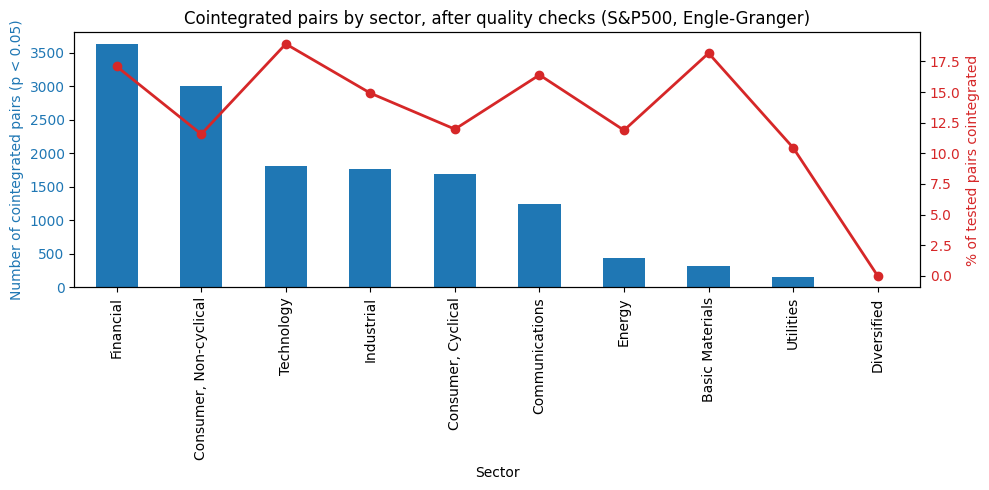

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 5))
summary['pairs_cointegrated'].plot(kind='bar', ax=ax1, color='#1f77b4')
ax1.set_ylabel('Number of cointegrated pairs (p < 0.05)', color='#1f77b4')
ax1.set_xlabel('Sector')
ax1.tick_params(axis='y', labelcolor='#1f77b4')

ax2 = ax1.twinx()
ax2.plot(ax1.get_xticks(), summary['percentage_cointegrated'] * 100, color='#d62728', marker='o', linewidth=2)
ax2.set_ylabel('% of tested pairs cointegrated', color='#d62728')
ax2.tick_params(axis='y', labelcolor='#d62728')

ax1.set_title('Cointegrated pairs by sector, after quality checks (S&P500, Engle-Granger)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

* **Financial** still has the most cointegrated pairs in absolute terms (3,625), with a high cointegration rate (17.1%), close to what Europe showed (19.5%). This is consistent with it being the largest sector on both markets.
* **Technology** is again among the most cohesive sectors (18.9%, versus 21.2% in Europe), but also **Basic Materials** is notable, at 18.2% here against only 9-10% in Europe.
* **Energy**, which stood out in Europe (18.3%), is instead among the weaker sectors here (11.9%).
* **Consumer Cyclical** and **Utilities** stay low in both markets (10-12%).
* **Diversified** has too few pairs tested (2) to draw any conclusion from.


***Top-15 pairs***

As for Europe, the 15 pairs with the lowest p-value are shown below.

In [ ]:
top_pairs = pairs_final.sort_values(['p_min', 'n_obs'], ascending=[True, False]).head(15).reset_index(drop=True)
top_pairs[['settore', 'A', 'B', 'p_min', 'n_obs', 'return_corr']].rename(columns={'settore':'sector'})

,sector,A,B,p_min,n_obs,return_corr
0,Technology,PALM UQ Equity,AMCC UQ Equity,4.933667e-22,2693,0.287127
1,Energy,SXCL UQ Equity,1539941D UN Equity,4.535442e-19,1152,0.141897
2,Communications,1518855D US Equity,0772031D UN Equity,1.016304e-18,2934,0.174370
3,Technology,PALM UQ Equity,BMC UN Equity,3.070884e-17,2249,0.250474
4,Financial,1558530D UN Equity,HST UN Equity,4.110529e-17,1186,0.037589
5,Technology,PALM UQ Equity,PMCS UQ Equity,1.298208e-14,2693,0.297604
6,Technology,PALM UQ Equity,PMCS UW Equity,1.298208e-14,2693,0.297604
7,"Consumer, Non-cyclical",ADCT UQ Equity,AET UN Equity,1.491026e-14,2607,0.160405
8,"Consumer, Non-cyclical",ADCT UW Equity,AET UN Equity,1.491026e-14,2607,0.160405
9,Financial,AVATQ US Equity,BRK/B UN Equity,2.654432e-14,2055,-0.001892


---
## ***Phase 3 - Validation***

The same out-of-sample validation approach used for Europe is applied here.


### **Why the lowest p-value is not enough?**

As for Europe, we start by checking whether the single best candidate by p-value actually holds up.

The pair with the lowest p-value from Phase 2 is `PALM UQ Equity` and `AMCC UQ Equity`.


In [ ]:
warnings.filterwarnings('ignore')

p_tr, p_te, beta, r2, n = validate_out_of_sample('PALM UQ Equity', 'AMCC UQ Equity')
print(f"PALM UQ / AMCC UQ  (the best by p-value in Phase 2)")
print(f"  n_obs={n}, R^2={r2:.4f}")
print(f"  ADF train: p={p_tr:.5f}  {'PASSED' if p_tr<0.05 else 'NOT passed'}")
print(f"  ADF test:  p={p_te:.5f}  {'PASSED' if p_te<0.05 else 'NOT passed'}")

PALM UQ / AMCC UQ  (the best by p-value in Phase 2)
  n_obs=2693, R^2=0.8808
  ADF train: p=0.00000  PASSED
  ADF test:  p=0.45995  NOT passed


The pair passes the training period, but fails completely on the test period. As we saw in the European data, a near-zero full-sample p-value in Phase 2 does not guarantee a stable relationship.


### **Widening the search**
So, we apply the same out-of-sample validation to a wider set of candidates.

In [ ]:
candidates = pairs_final[pairs_final['n_obs'] > 1000].sort_values('p_min').head(150).reset_index(drop=True)

t0 = time.time()
results = []
for _, r in candidates.iterrows():
    try:
        p_tr, p_te, beta, r2, n = validate_out_of_sample(r['A'], r['B'])
        results.append({'settore': r['settore'], 'A': r['A'], 'B': r['B'], 'n_obs': n,
                        'p_train': p_tr, 'p_test': p_te, 'beta': beta, 'r2': r2})
    except Exception:
        continue

validation = pd.DataFrame(results)

robust = validation[(validation['p_train'] < 0.05) & (validation['p_test'] < 0.05)]
print(f"\nPairs passing ADF both in train and test: {len(robust)} out of {len(validation)} tested ({len(robust)/len(validation):.1%})")


Pairs passing ADF both in train and test: 11 out of 150 tested (7.3%)


Only 11 pairs out of 150 (7.3%) pass the ADF test in both the training and test periods.

In [ ]:
sector_name_lookup = dict(zip(sector_map['ticker'], sector_map['nome']))

robust_display = robust.copy()

robust_display['period_A'] = robust_display['A'].apply(stock_quality)
robust_display['period_B'] = robust_display['B'].apply(stock_quality)

robust_display = robust_display.sort_values('p_test')

robust_display[['settore','A','period_A','B','period_B',
                'n_obs','p_train','p_test','r2']].rename(columns={'settore':'sector'})

,sector,A,period_A,B,period_B,n_obs,p_train,p_test,r2
133,Financial,WAMUQ UQ Equity,1994-12-27 -> 1998-12-08,SITC UN Equity,1993-02-02 -> 2018-11-30,1031,3.326747e-05,0.000175,0.909120
84,Communications,RHDCQ UN Equity,1990-01-02 -> 2008-12-31,571300Q UN Equity,1990-01-02 -> 2000-06-30,2739,8.440617e-03,0.000202,0.581635
72,Communications,WCOEQ UQ Equity,1990-01-02 -> 2002-07-29,3054Q UN Equity,1990-01-02 -> 1999-10-08,2549,2.639303e-04,0.000528,0.886774
80,Financial,301710Q UN Equity,1990-01-02 -> 2000-11-03,GDW UN Equity,1990-01-02 -> 2006-09-29,2829,1.350957e-03,0.001774,0.881304
139,Communications,253647Q UN Equity,1990-01-02 -> 2001-01-11,CMCSA UW Equity,1990-01-02 -> 2018-11-30,2878,1.014501e-04,0.006081,0.850123
138,Communications,253647Q UN Equity,1990-01-02 -> 2001-01-11,CMCSA UQ Equity,1990-01-02 -> 2018-11-30,2878,1.014501e-04,0.006081,0.850123
64,Technology,ADI UN Equity,1990-01-02 -> 2018-11-30,LLTC UW Equity,1990-01-02 -> 2017-03-10,5804,5.119169e-07,0.016883,0.933394
65,Technology,ADI UN Equity,1990-01-02 -> 2018-11-30,LLTC UQ Equity,1990-01-02 -> 2017-03-10,5804,5.119169e-07,0.016883,0.933394
136,Communications,BBBY UQ Equity,1992-06-05 -> 2018-11-30,3054Q UN Equity,1990-01-02 -> 1999-10-08,1916,2.256733e-03,0.044618,0.804824
135,Communications,BBBY UW Equity,1992-06-05 -> 2018-11-30,3054Q UN Equity,1990-01-02 -> 1999-10-08,1916,2.256733e-03,0.044618,0.804824


We select the pair `ADI UN` / `LLTC UW`, because among the candidates it has the strongest R-squared (0.93), the longest sample (5,804 observations, 1990-2017), a testing p-value with a solid margin below the 5% threshold, and no crisis event in its history (unlike the others).

### **Estimating the relationship**


In [ ]:
x = prices['ADI UN Equity'].dropna()
y = prices['LLTC UW Equity'].dropna()

common = x.index.intersection(y.index)
x, y = x.loc[common], y.loc[common]

n = len(common)
split = int(n * 0.7)
x_train, y_train = x.iloc[:split], y.iloc[:split]
x_test, y_test = x.iloc[split:], y.iloc[split:]

In [ ]:
X_train = sm.add_constant(x_train)
model = sm.OLS(y_train, X_train).fit()
alpha, beta = model.params.iloc[0], model.params.iloc[1]

print(f"Hedge ratio (beta): {beta:.5f}")
print(f"Intercept (alpha): {alpha:.4f}")
print(f"Regression R^2: {model.rsquared:.4f}")

Hedge ratio (beta): 0.83868
Intercept (alpha): 3.0586
Regression R^2: 0.9334


The pair is strong because:
- The hedge ratio of 0.84 is positive, meaning the two stocks tend to move in the same direction, and its value close to 1 reflects a close co-movement between them.

- The R^2 of 0.93 indicates a very strong linear relationship between the two stocks.

### **ADF test**
As for Europe, we applied the ADF test for stationarity.

In [ ]:
spread_train = y_train - (alpha + beta * x_train)
spread_test = y_test - (alpha + beta * x_test)

adf_train = adfuller(spread_train, maxlag=1)
adf_test = adfuller(spread_test, maxlag=1)

print(f"ADF on residual (TRAIN): statistic={adf_train[0]:.3f}, p-value={adf_train[1]:.5f}")
print(f"ADF on residual (TEST):  statistic={adf_test[0]:.3f}, p-value={adf_test[1]:.5f}")
print()
print("The test is passed (stationary spread) if the p-value is below 0.05.")
print(f"Train: {'PASSED' if adf_train[1] < 0.05 else 'NOT passed'}")
print(f"Test:  {'PASSED' if adf_test[1] < 0.05 else 'NOT passed'}")

ADF on residual (TRAIN): statistic=-5.781, p-value=0.00000
ADF on residual (TEST):  statistic=-3.258, p-value=0.01688

The test is passed (stationary spread) if the p-value is below 0.05.
Train: PASSED
Test:  PASSED


As for Europe, the spread passes the ADF test in both periods, confirming the pair is genuinely cointegrated. The test-period p-value (0.017) is weaker than the train-period one (0.00000), as expected, but with a comfortable margin below the 5% threshold.

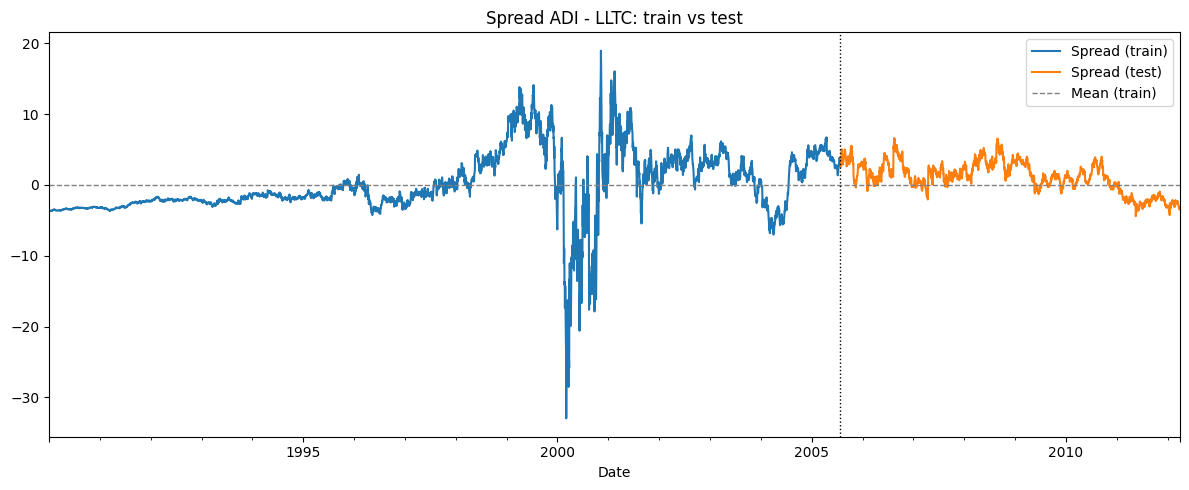

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))
spread_train.plot(ax=ax, label='Spread (train)', color='#1f77b4')
spread_test.plot(ax=ax, label='Spread (test)', color='#ff7f0e')
ax.axhline(spread_train.mean(), color='gray', linestyle='--', linewidth=1, label='Mean (train)')
ax.axvline(spread_train.index[-1], color='black', linestyle=':', linewidth=1)
ax.set_title('Spread ADI - LLTC: train vs test')
ax.legend()
plt.tight_layout()
plt.show()

The spread shows an extreme swing between 1999 and 2001, reaching -33 to +19, consistent with the dot-com crash. Outside that period, the spread oscillates in a much narrower band, and the test period continues in a range similar to the most recent training years, consistent with the ADF test passing in both periods.

***Mean-reversion half-life***

Now, we estimate how quickly the spread reverts to its mean.

In [ ]:
spread_lag = spread_train.shift(1).dropna()
spread_delta = spread_train.diff().dropna()
spread_lag = spread_lag.loc[spread_delta.index]

hl_model = sm.OLS(spread_delta, sm.add_constant(spread_lag)).fit()
lam = hl_model.params.iloc[1]
half_life = -np.log(2) / lam if lam < 0 else np.nan

print(f"Mean-reversion coefficient (lambda): {lam:.5f}")
print(f"Half-life: {half_life:.1f} trading days")

Mean-reversion coefficient (lambda): -0.02052
Half-life: 33.8 trading days


Lambda is negative (-0.02052), confirming mean reversion, which translates into a half-life of 33.8 trading days (about 1 month), which is a fast reversion.

***Z-score of the spread***

Now, the spread is converted into a z-score.

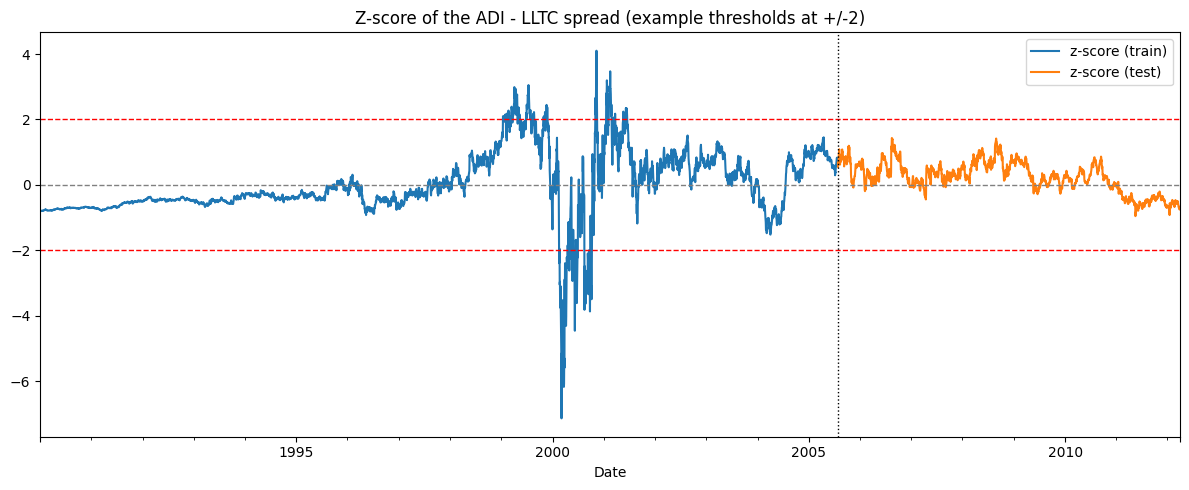

In [ ]:
mu_train = spread_train.mean()
sigma_train = spread_train.std()

z_train = (spread_train - mu_train) / sigma_train
z_test = (spread_test - mu_train) / sigma_train

fig, ax = plt.subplots(figsize=(12, 5))
z_train.plot(ax=ax, label='z-score (train)', color='#1f77b4')
z_test.plot(ax=ax, label='z-score (test)', color='#ff7f0e')
for level, color in [(2, 'red'), (-2, 'red'), (0, 'gray')]:
    ax.axhline(level, color=color, linestyle='--', linewidth=1)
ax.axvline(z_train.index[-1], color='black', linestyle=':', linewidth=1)
ax.set_title('Z-score of the ADI - LLTC spread (example thresholds at +/-2)')
ax.legend()
plt.tight_layout()
plt.show()

In the test period, the z-score never reaches the ±2 threshold shown here: the same limitation of fixed thresholds already seen for the European pair, which Phase 4 addresses with a rolling window instead.

---
## ***Phase 4 — Portfolio***
As for Europe, the same out-of-sample validation used in Phase 3 for a single pair is now applied to every remaining candidate pair.

In [ ]:
t0 = time.time()
full_results = []
for _, r in pairs_final.iterrows():
    try:
        p_tr, p_te, beta, r2, n = validate_out_of_sample(r['A'], r['B'])
        full_results.append({'settore': r['settore'], 'A': r['A'], 'B': r['B'],
                             'n_obs': n, 'p_train': p_tr, 'p_test': p_te})
    except Exception:
        continue

full_validation = pd.DataFrame(full_results)

robust = full_validation[(full_validation['p_train']<0.05) & (full_validation['p_test']<0.05)]
print(f"Robust pairs (ADF passed in train and test): {len(robust)} out of {len(full_validation)} ({len(robust)/len(full_validation):.2%})")

Robust pairs (ADF passed in train and test): 600 out of 14057 (4.27%)


Only 600 pairs out of 14,057 (4.27%) pass the validation both in train and in test.

This confirms what we saw with the European dataset: a strong cointegration p-value on the full sample is a weak predictor of future stability.

Still, 600 pairs are more than enough to build a well-diversified portfolio.

### ***Portfolio selection***
The portfolio is built with the same diversification rules used for Europe.


In [ ]:
candidates = robust[robust['n_obs'] >= 750].sort_values('p_test')

N_TARGET = 20
MAX_PER_SECTOR = 5
used, sector_count, final_portfolio = set(), {}, []
for _, r in candidates.iterrows():
    if r['A'] in used or r['B'] in used:
        continue
    if sector_count.get(r['settore'], 0) >= MAX_PER_SECTOR:
        continue
    final_portfolio.append(r)
    used.add(r['A']); used.add(r['B'])
    sector_count[r['settore']] = sector_count.get(r['settore'], 0) + 1
    if len(final_portfolio) >= N_TARGET:
        break

final_portfolio = pd.DataFrame(final_portfolio)
print(f"Final portfolio:")
final_portfolio[['settore','A','B','n_obs','p_train','p_test']].rename(columns={'settore':'sector'})

Final portfolio:


,sector,A,B,n_obs,p_train,p_test
2115,"Consumer, Cyclical",COC UN Equity,GPC UN Equity,817,0.030374,4.004502e-07
6982,Financial,2196Q UN Equity,TROW UW Equity,2282,0.040606,3.667481e-05
4602,"Consumer, Non-cyclical",2731112Q US Equity,PEP UN Equity,2742,0.025516,7.041892e-05
9246,Financial,SPG UN Equity,WAMUQ UQ Equity,1031,0.013937,1.481245e-04
3338,"Consumer, Non-cyclical",EFX UN Equity,MO UN Equity,7544,0.001675,1.700723e-04
569,Communications,RHDCQ UN Equity,571300Q UN Equity,2739,0.008441,2.020832e-04
6901,Financial,BAC UN Equity,ZION UW Equity,7544,0.002397,2.040522e-04
7290,Financial,2036Q UN Equity,1618Q US Equity,1934,0.022634,2.521906e-04
11448,Industrial,PH UN Equity,ROK UN Equity,5740,0.045113,3.092042e-04
8062,Financial,MEL UN Equity,IVZ UN Equity,3091,0.001165,3.134070e-04


The final portfolio spans 6 of the 10 sectors, with Financial and Consumer Non-cyclical each hitting the cap of 5 pairs.

`ADI UN` / `LLTC UW`, the pair examined in Phase 3, passed validation but didn't make it into the final portfolio, because `LLTC` is also part of a stronger pair (`LLTC UQ` / `3153670Q UQ`).

### ***Trading rules***
The same trading rules described for Europe are used here without any change.

In [ ]:
backtest_results = {}
for _, r in final_portfolio.iterrows():
    name = f"{r['A']} / {r['B']}"
    try:
        backtest_results[name] = backtest_pair(r['A'], r['B'])
    except Exception as e:
        print(f"Error on {name}: {e}")

print(f"Pairs with completed backtest: {len(backtest_results)}")

Pairs with completed backtest: 20


As for Europe, all 20 pairs selected produce a complete backtest (20/20).


### ***Equal-weight portfolio and comparison with the benchmark***
As for Europe, each pair contributes an equal share of the portfolio, and the result is compared against the S&P500 benchmark over the same period.

In [ ]:
pair_rets = pd.concat([v['ret_series'] for v in backtest_results.values()], axis=1)
pair_rets.columns = list(backtest_results.keys())
pair_rets_filled = pair_rets.fillna(0)

port_ret = pair_rets_filled.mean(axis=1)
port_equity = (1 + port_ret).cumprod()
port_peak = port_equity.cummax()
port_dd = (port_equity - port_peak) / port_peak
port_sharpe = np.sqrt(52) * port_ret.mean() / port_ret.std() if port_ret.std() > 0 else 0

# how many pairs have real data (not zero-filled) in each week
n_active = pair_rets.notna().sum(axis=1)

# SXXP benchmark over the same overall period, same weekly frequency
ac_w = ac_series.resample('W-FRI').last().dropna()
ac_test = ac_w.loc[port_ret.index[0]:port_ret.index[-1]]
bench_ret = ac_test.pct_change().fillna(0)
bench_equity = (1 + bench_ret).cumprod()
bench_peak = bench_equity.cummax()
bench_dd = (bench_equity - bench_peak) / bench_peak
bench_sharpe = np.sqrt(52) * bench_ret.mean() / bench_ret.std() if bench_ret.std() > 0 else 0

summary_table = pd.DataFrame({
    'Portfolio': [
        f"{port_equity.iloc[-1] - 1:.1%}",
        f"{port_sharpe:.2f}",
        f"{port_dd.min():.1%}",
        f"{port_ret.std() * np.sqrt(52):.1%}",
    ],
    'Benchmark': [
        f"{bench_equity.iloc[-1] - 1:.1%}",
        f"{bench_sharpe:.2f}",
        f"{bench_dd.min():.1%}",
        f"{bench_ret.std() * np.sqrt(52):.1%}",
    ],
}, index=['Total return', 'Annualized Sharpe', 'Max drawdown', 'Annualized volatility'])
summary_table

,Portfolio,Benchmark
Total return,50.2%,495.8%
Annualized Sharpe,1.46,0.51
Max drawdown,-1.2%,-56.2%
Annualized volatility,1.2%,16.6%


The portfolio delivers a Sharpe ratio nearly 3x higher than the benchmark (1.46 vs 0.51), with a much smaller drawdown (-1.2% vs -56.2%) and lower volatility (1.2% vs 16.6% annualized). As with Europe, total return is lower for the strategy (50.2% vs 495.8%).

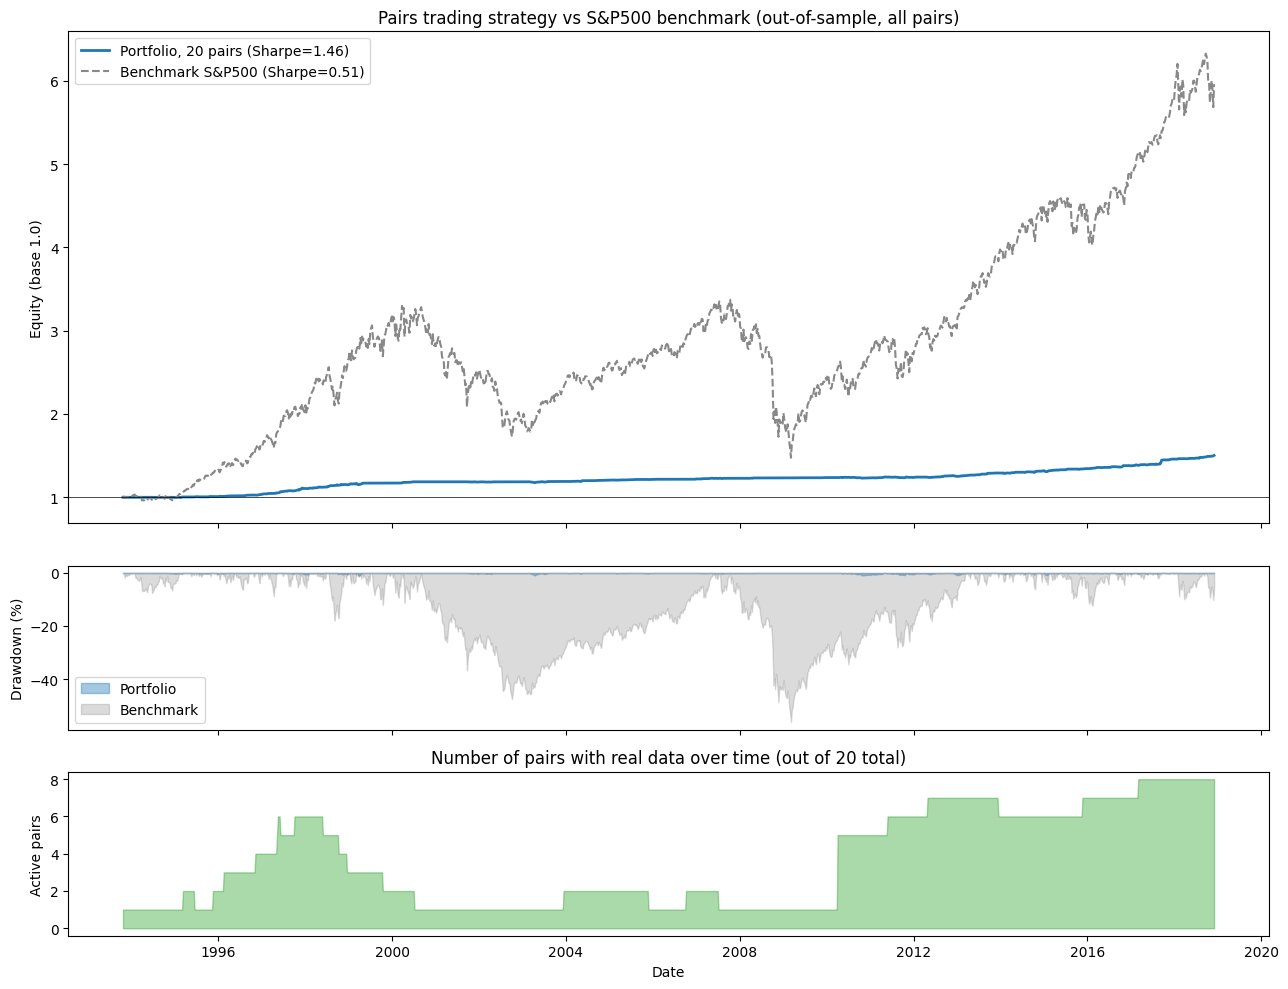

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True, gridspec_kw={'height_ratios':[3,1,1]})

axes[0].plot(port_equity.index, port_equity, color='#1f77b4', lw=2, label=f'Portfolio, 20 pairs (Sharpe={port_sharpe:.2f})')
axes[0].plot(bench_equity.index, bench_equity, color='#888', lw=1.5, ls='--', label=f'Benchmark S&P500 (Sharpe={bench_sharpe:.2f})')
axes[0].axhline(1, color='black', lw=0.5)
axes[0].set_ylabel('Equity (base 1.0)')
axes[0].set_title('Pairs trading strategy vs S&P500 benchmark (out-of-sample, all pairs)')
axes[0].legend()

axes[1].fill_between(port_dd.index, port_dd*100, 0, color='#1f77b4', alpha=0.4, label='Portfolio')
axes[1].fill_between(bench_dd.index, bench_dd*100, 0, color='#888', alpha=0.3, label='Benchmark')
axes[1].set_ylabel('Drawdown (%)')
axes[1].legend()

axes[2].fill_between(n_active.index, n_active, 0, color='#2ca02c', alpha=0.4)
axes[2].set_ylabel('Active pairs')
axes[2].set_xlabel('Date')
axes[2].set_title('Number of pairs with real data over time (out of 20 total)')

plt.tight_layout()
plt.show()

In the top panel, the benchmark shows a long, strong uptrend interrupted by two sharp collapses (the dot-com crash and the 2008 financial crisis), while the portfolio follows a much smoother increasing path.

The difference is even more visible in the second panel: the benchmark's drawdown exceeds -55% twice, while the portfolio's drawdown stays close to zero for almost the entire sample.

The bottom panel shows that relatively few pairs are active simultaneously for most of the sample, since the dataset spans nearly 29 years and different stocks enter and exit their price histories at very different points.

### ***Robustness check: pairs with near-complete history only***
As for Europe, the same portfolio construction is repeated restricting the candidates to pairs with a fully overlapping trading history.


In [ ]:
long_candidates = robust[robust['n_obs'] >= 4000].sort_values('p_test')

used2, sector_count2, long_portfolio = set(), {}, []
for _, r in long_candidates.iterrows():
    if r['A'] in used2 or r['B'] in used2:
        continue
    if sector_count2.get(r['settore'], 0) >= MAX_PER_SECTOR:
        continue
    long_portfolio.append(r)
    used2.add(r['A']); used2.add(r['B'])
    sector_count2[r['settore']] = sector_count2.get(r['settore'], 0) + 1
    if len(long_portfolio) >= N_TARGET:
        break
long_portfolio = pd.DataFrame(long_portfolio)

long_results = {}
for _, r in long_portfolio.iterrows():
    name = f"{r['A']} / {r['B']}"
    try:
        long_results[name] = backtest_pair(r['A'], r['B'])
    except Exception:
        continue

pair_rets_L = pd.concat([v['ret_series'] for v in long_results.values()], axis=1)
pair_rets_L.columns = list(long_results.keys())
port_ret_L = pair_rets_L.mean(axis=1)
port_equity_L = (1 + port_ret_L).cumprod()
port_sharpe_L = np.sqrt(52) * port_ret_L.mean() / port_ret_L.std() if port_ret_L.std() > 0 else 0
port_dd_L = (port_equity_L - port_equity_L.cummax()) / port_equity_L.cummax()

ac_test_L = ac_w.loc[port_ret_L.index[0]:port_ret_L.index[-1]]
bench_ret_L = ac_test_L.pct_change().fillna(0)
bench_equity_L = (1 + bench_ret_L).cumprod()
bench_sharpe_L = np.sqrt(52) * bench_ret_L.mean() / bench_ret_L.std() if bench_ret_L.std() > 0 else 0
bench_dd_L = (bench_equity_L - bench_equity_L.cummax()) / bench_equity_L.cummax()

summary_table_L = pd.DataFrame({
    'Portfolio (long history)': [
        f"{port_equity_L.iloc[-1] - 1:.1%}",
        f"{port_sharpe_L:.2f}",
        f"{port_dd_L.min():.1%}",
    ],
    'Benchmark': [
        f"{bench_equity_L.iloc[-1] - 1:.1%}",
        f"{bench_sharpe_L:.2f}",
        f"{bench_dd_L.min():.1%}",
    ],
}, index=['Total return', 'Annualized Sharpe', 'Max drawdown'])
summary_table_L

,Portfolio (long history),Benchmark
Total return,209.6%,131.8%
Annualized Sharpe,0.96,0.37
Max drawdown,-12.4%,-56.2%


Restricting to pairs with near-complete history changes the picture in the opposite direction from Europe: the Sharpe ratio here is lower than the main portfolio's (0.96 vs 1.46), and the maximum drawdown is larger than the main portfolio's (-12.4% vs -1.2%), though still far smaller than the benchmark's (-56.2%). Total return, on the other hand, is much higher (209.6% vs 50.2%), since this window benefits from more pairs being simultaneously active.

This is a useful counterpoint to the European result, where the long-history portfolio was the stronger one: it shows that restricting to a fully overlapping sample does not automatically improve results.

### ***Saving results for future comparisons***


In [ ]:
us_results = {
    'main': {
        'sharpe': port_sharpe, 'max_dd': port_dd.min(), 'total_return': port_equity.iloc[-1] - 1,
        'bench_sharpe': bench_sharpe, 'bench_max_dd': bench_dd.min(), 'bench_total_return': bench_equity.iloc[-1] - 1,
        'period': f"{port_ret.index[0].date()} to {port_ret.index[-1].date()}"
    },
    'long': {
        'sharpe': port_sharpe_L, 'max_dd': port_dd_L.min(), 'total_return': port_equity_L.iloc[-1] - 1,
        'bench_sharpe': bench_sharpe_L, 'bench_max_dd': bench_dd_L.min(), 'bench_total_return': bench_equity_L.iloc[-1] - 1,
        'period': f"{port_ret_L.index[0].date()} to {port_ret_L.index[-1].date()}"
    }
}

---
# **Part 3 - Cross-Market Comparison**

Both markets were analyzed with the exact same methodology, independently.

Now, let's compare the results.

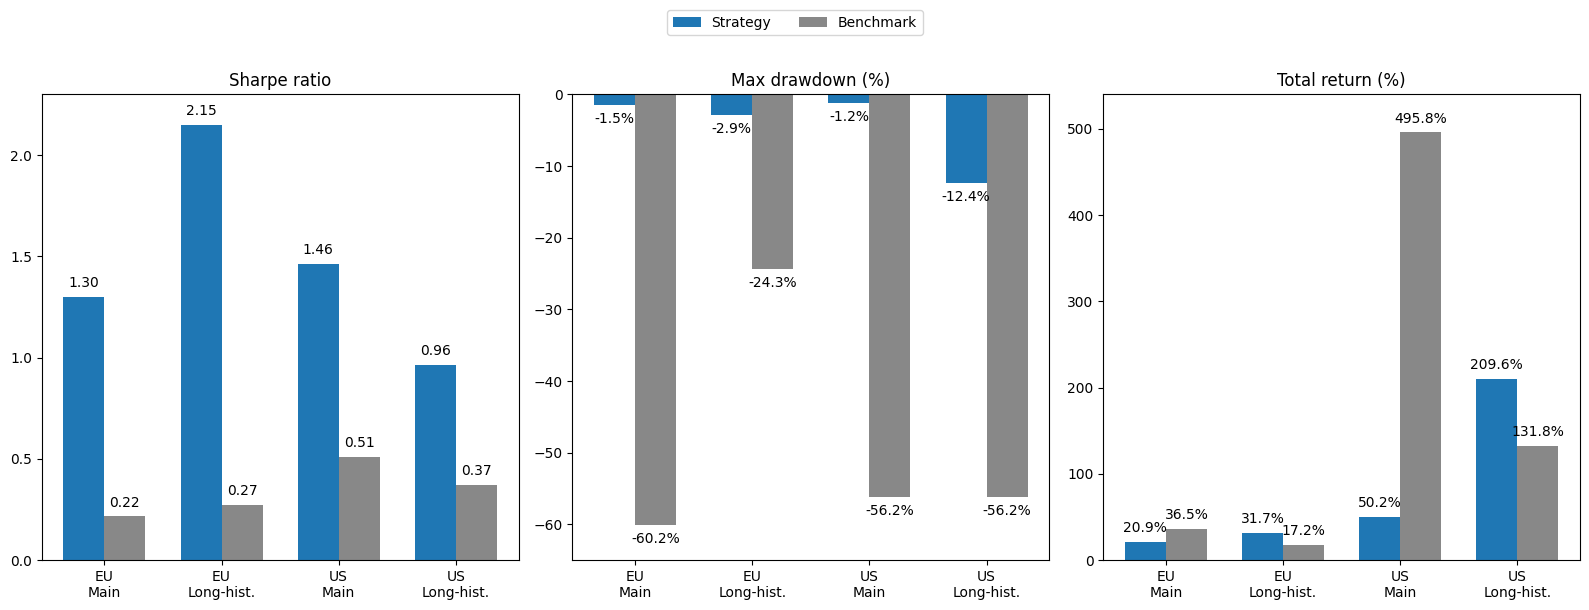

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

labels = ['EU\nMain', 'EU\nLong-hist.', 'US\nMain', 'US\nLong-hist.']
rows = [eu_results['main'], eu_results['long'], us_results['main'], us_results['long']]

sharpe_port = [r['sharpe'] for r in rows]
sharpe_bench = [r['bench_sharpe'] for r in rows]
dd_port = [r['max_dd'] * 100 for r in rows]
dd_bench = [r['bench_max_dd'] * 100 for r in rows]
ret_port = [r['total_return'] * 100 for r in rows]
ret_bench = [r['bench_total_return'] * 100 for r in rows]

x = np.arange(len(labels))
width = 0.35

# Sharpe ratio
bars1 = axes[0].bar(
    x - width/2, sharpe_port, width,
    label='Strategy', color='#1f77b4'
)
bars2 = axes[0].bar(
    x + width/2, sharpe_bench, width,
    label='Benchmark', color='#888'
)

axes[0].bar_label(bars1, fmt='%.2f', padding=5)
axes[0].bar_label(bars2, fmt='%.2f', padding=5)
axes[0].set_title('Sharpe ratio')
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylim(0, 2.3)


# Max drawdown
bars3 = axes[1].bar(
    x - width/2, dd_port, width,
    color='#1f77b4'
)
bars4 = axes[1].bar(
    x + width/2, dd_bench, width,
    color='#888'
)

axes[1].bar_label(bars3, fmt='%.1f%%', padding=5)
axes[1].bar_label(bars4, fmt='%.1f%%', padding=5)
axes[1].set_title('Max drawdown (%)')
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_ylim(-65, 0)


# Total return
bars5 = axes[2].bar(
    x - width/2, ret_port, width,
    color='#1f77b4'
)
bars6 = axes[2].bar(
    x + width/2, ret_bench, width,
    color='#888'
)

axes[2].bar_label(bars5, fmt='%.1f%%', padding=5)
axes[2].bar_label(bars6, fmt='%.1f%%', padding=5)
axes[2].set_title('Total return (%)')
axes[2].set_xticks(x)
axes[2].set_xticklabels(labels)
axes[2].set_ylim(0, 540)


# Legend
fig.legend(
    [bars1, bars2],
    ['Strategy', 'Benchmark'],
    loc='upper center',
    ncol=2,
    bbox_to_anchor=(0.5, 1.02)
)

plt.tight_layout(rect=[0, 0, 1, 0.93])

plt.show()

Across all four portfolio/market combinations, the strategy's Sharpe ratio beats the benchmark's. Drawdown is also far lower for the strategy in three cases, and still clearly better in the fourth.

Total returns are lower for the strategy in the two main portfolios, but higher in both long-history portfolios, where more pairs are simultaneously active.

---
# **Conclusions**

In conclusion, the same pairs trading pipeline was successfully built and validated independently on both the European and US universes, with the strategy consistently showing a better risk-return profile than the benchmark, though with a lower total return.

The main limitations are that the backtests don't include real trading costs (e.g. commissions), so real results would likely be somewhat lower. There is also always a risk that one of the two companies in a pair goes bankrupt or gets delisted while the position is open, something no statistical test can fully protect against. Finally, the data used stops in 2018, so the results describe that specific historical period rather than current market conditions.

These limits could be addressed by future developments, such as modeling real transaction costs, adding stronger risk controls, and extending the analysis to more recent data.

